# 02 Exploratory Data Analysis: Toko Pertanian Multikanal

**Capstone:** Pengelolaan Persediaan dan Pemantauan Penjualan Bulanan pada Toko Pertanian Multikanal (Asah by Dicoding)

**Data:** tabel bersih hasil `01_data_wrangling.ipynb` di `data/processed/`

### Tujuan notebook
1. **Exploratory Data Analysis**: mengenal isi setiap tabel bersih (distribusi, tren, keanehan) sebelum menjawab pertanyaan.
2. **Visualization & Explanatory Analysis**: menjawab pertanyaan bisnis yang bersifat deskriptif, yaitu **Q1–Q6 dan Q12**.
3. **Aturan stok** (`reorder_settings`): titik pesan ulang dan batas memecah per SKU, dipakai untuk Q4, Q5, dan nanti Q8 dan Q10.
4. **Pola penjualan untuk modeling**: tren, musim, dan SKU yang jarang terjual, sebagai bekal forecast Q7–Q11 di `03_modeling.ipynb`.

### Aturan yang dipakai di seluruh notebook
- **Angka penjualan strict**: hanya `transaction_items`. Penjualan yang ditolak karena nama ambigu (`penjualan_ambigu`, 0,36% omzet offline) **tidak** ikut dihitung, sama seperti di dashboard.
- Omzet offline = subtotal, omzet online = netto. Tanggal online = tanggal pesanan (`order_date`).
- "Unit terjual" = jumlah qty dalam satuan jual masing-masing SKU (botol, bungkus, kemasan 0,5 kg, dan seterusnya), jadi tidak dijumlahkan dalam kg.
- Bulan acuan terakhir = **Okt 2026**; tanggal acuan stok = **31 Okt 2026**; "12 bulan terakhir" = Nov 2025 sampai Okt 2026.

## 1. Import Library dan Memuat Data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

ROOT = Path("..").resolve()
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# Gaya grafik: garis tipis, grid samar, tanpa bingkai atas/kanan
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 2, "legend.frameon": False,
})
# Warna tetap per kanal (urutan palet kategorikal yang sudah divalidasi aman untuk buta warna)
WARNA_KANAL = {"Offline": "#2a78d6", "Shopee": "#eb6834", "Tokopedia": "#1baf7a", "TikTok Shop": "#eda100"}
WARNA_UTAMA = "#2a78d6"
WARNA_REDUP = "#c3c2b7"
KANAL_BAKU = list(WARNA_KANAL)


def format_rupiah(nilai, _=None):
    # Format angka sumbu: 1.250.000.000 -> 'Rp1,25 M', 120.000.000 -> 'Rp120 jt'.
    if abs(nilai) >= 1e9:
        return f"Rp{nilai / 1e9:,.2f} M".replace(".", ",")
    if abs(nilai) >= 1e7:
        return f"Rp{nilai / 1e6:,.0f} jt"
    if abs(nilai) >= 1e6:
        return f"Rp{nilai / 1e6:.1f} jt".replace(".", ",").replace(",0 jt", " jt")
    return f"Rp{nilai:,.0f}".replace(",", ".")


def rupiah(nilai):
    # Format angka untuk teks/tabel: 3237619500 -> 'Rp3.237.619.500'.
    return f"Rp{nilai:,.0f}".replace(",", ".")

In [2]:
def baca(nama, **kwargs):
    return pd.read_csv(PROCESSED / f"{nama}.csv", **kwargs)

channels = baca("channels")
products = baca("products")
suppliers = baca("suppliers")
transactions = baca("transactions", parse_dates=["tanggal"])
items = baca("transaction_items", parse_dates=["tanggal"])
finansial = baca("online_item_financials", parse_dates=["order_date"])
gerak = baca("stock_movements", parse_dates=["tanggal", "order_date"])
opname = baca("stock_opname", parse_dates=["tanggal"])
metrik = baca("marketplace_metrics", parse_dates=["periode_mulai", "periode_akhir"])
riwayat_harga = baca("product_price_history", parse_dates=["bulan"])
ambigu = baca("penjualan_ambigu", parse_dates=["tanggal"])
data_status = baca("data_status", parse_dates=["periode_mulai", "data_complete_until"])

ringkas = pd.DataFrame([{"tabel": n, "baris": len(d), "kolom": d.shape[1]} for n, d in {
    "channels": channels, "products": products, "suppliers": suppliers, "transactions": transactions,
    "transaction_items": items, "online_item_financials": finansial, "stock_movements": gerak,
    "stock_opname": opname, "marketplace_metrics": metrik, "product_price_history": riwayat_harga,
    "penjualan_ambigu": ambigu}.items()])
ringkas

,tabel,baris,kolom
0,channels,4,6
1,products,190,22
2,suppliers,7,4
3,transactions,35436,7
4,transaction_items,59946,11
5,online_item_financials,5053,22
6,stock_movements,66541,8
7,stock_opname,1062,10
8,marketplace_metrics,4130,15
9,product_price_history,8349,5


In [3]:
# Kolom bantu yang dipakai berulang: bulan, kategori, dan nama produk
AKHIR = pd.Timestamp("2026-10-31")
info = products.set_index("sku")
items["bulan"] = items["tanggal"].dt.to_period("M")
items["kategori"] = items["sku"].map(info["kategori"])
items["nama"] = items["sku"].map(info["nama"])
print("Periode item:", items["tanggal"].min().date(), "sampai", items["tanggal"].max().date())
print("Item tanpa kategori:", items["kategori"].isna().sum())
data_status[["kanal", "periode_mulai", "data_complete_until"]]

Periode item: 2023-11-01 sampai 2026-10-31
Item tanpa kategori: 0


,kanal,periode_mulai,data_complete_until
0,Offline,2023-11-01,2026-10-31
1,Shopee,2025-02-01,2026-10-31
2,TikTok Shop,2025-06-01,2026-10-31
3,Tokopedia,2025-02-01,2026-10-31
4,Stok (restok/retur/pemecahan/rakit),2023-11-04,2026-10-31
5,Metrik marketplace,2025-02-01,2026-10-31


## 2. Exploratory Data Analysis (EDA)

### 2.1 Explore `transaction_items`: omzet, unit, dan jumlah baris per kanal

In [4]:
per_kanal = (items.groupby("kanal")
             .agg(baris=("item_id", "size"), transaksi=("transaction_id", "nunique"), unit=("qty", "sum"),
                  omzet=("revenue", "sum"), sku=("sku", "nunique"), mulai=("tanggal", "min"), sampai=("tanggal", "max"))
             .reindex(KANAL_BAKU))
per_kanal["porsi_omzet_%"] = (per_kanal["omzet"] / per_kanal["omzet"].sum() * 100).round(1)
per_kanal["omzet_per_unit"] = (per_kanal["omzet"] / per_kanal["unit"]).round(0)
per_kanal

,baris,transaksi,unit,omzet,sku,mulai,sampai,porsi_omzet_%,omzet_per_unit
kanal,,,,,,,,,
Offline,54893,31310,109954,3.237620e+09,179,2023-11-01,2026-10-31,92.6,29445.0
Shopee,2293,1862,2889,1.169944e+08,154,2025-02-01,2026-10-31,3.3,40497.0
Tokopedia,884,731,1166,4.656427e+07,132,2025-02-09,2026-10-31,1.3,39935.0
TikTok Shop,1876,1533,2396,9.358527e+07,155,2025-06-01,2026-10-31,2.7,39059.0


In [5]:
print(items[["qty", "harga_satuan", "revenue"]].describe(percentiles=[0.5, 0.9, 0.99]).round(0))
print("\nQty terbanyak dalam satu baris:")
items.nlargest(5, "qty")[["tanggal", "kanal", "sku", "nama", "qty", "harga_satuan", "revenue"]]

           qty  harga_satuan   revenue
count  59946.0       59946.0   59946.0
mean       2.0       34883.0   58299.0
std        2.0       28547.0   61887.0
min        1.0        2667.0     929.0
50%        1.0       27000.0   37500.0
90%        4.0       68875.0  126000.0
99%        8.0      152000.0  327000.0
max       20.0      191468.0  987000.0

Qty terbanyak dalam satu baris:


,tanggal,kanal,sku,nama,qty,harga_satuan,revenue
732,2023-11-15,Offline,KCL,KCL Curah,20,12000.0,240000.0
932,2023-11-18,Offline,KCL,KCL Curah,20,12000.0,240000.0
1050,2023-11-21,Offline,DLMT,Kapur Dolomite,20,3000.0,57500.0
1405,2023-11-25,Offline,KCL,KCL Curah,20,12000.0,240000.0
1612,2023-12-01,Offline,DLMT,Kapur Dolomite,20,3000.0,58000.0


**Insight:**
- **Offline menguasai 92,6% omzet** (Rp3,24 miliar dari Rp3,49 miliar selama 36 bulan). Ketiga marketplace bersama-sama baru 7,4%, dan Tokopedia yang terkecil (1,3%).
- Omzet per unit di marketplace (sekitar Rp39–40 ribu) lebih tinggi daripada offline (Rp29 ribu). Penyebabnya: harga online memang lebih mahal (lihat 2.5), dan barang curah murah per kemasan (KCL, Dolomit, Urea) hampir semuanya terjual offline.
- Satu baris transaksi biasanya hanya 1–2 unit (median 1, persentil 99 = 8). Qty terbesar 20 kemasan KCL atau Dolomit, wajar untuk pembelian pupuk curah. Setelah wrangling, tidak ada lagi qty ekstrem seperti 10× lipat.

### 2.2 Explore tren bulanan total

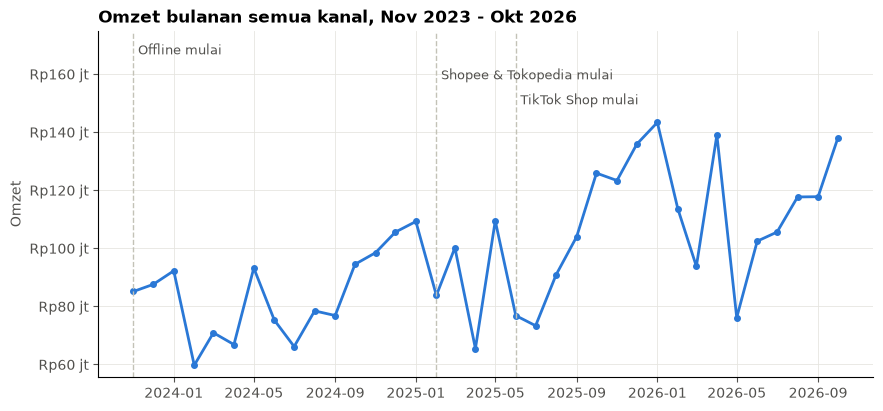

,mulai,akhir
kanal,,
Offline,2023-11-01,2026-10-31
Shopee,2025-02-01,2026-10-31
Tokopedia,2025-02-09,2026-10-31
TikTok Shop,2025-06-01,2026-10-31


bulan,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
omzet,Rp85.072.500,Rp87.521.000,Rp92.195.500,Rp59.675.000,Rp70.859.500,Rp66.799.500,Rp93.155.000,Rp75.240.500,Rp66.111.500,Rp78.395.500,Rp76.795.500,Rp94.444.500,Rp98.424.000,Rp105.519.000,Rp109.176.500,Rp83.718.942,Rp100.142.053,Rp65.420.432,Rp109.413.871,Rp76.784.188,Rp73.289.710,Rp90.840.524,Rp103.911.452,Rp125.837.555,Rp123.292.399,Rp135.821.413,Rp143.290.208,Rp113.537.964,Rp93.731.055,Rp138.953.527,Rp76.093.029,Rp102.402.796,Rp105.546.447,Rp117.627.203,Rp117.715.969,Rp138.007.701
unit,3216,3178,3352,2294,2379,2467,3442,2786,2347,2691,2663,3198,3505,3696,3616,2721,3223,2177,3821,2763,2430,2964,3387,3926,4086,4244,4683,3744,2892,4347,2404,3299,3313,3558,3568,4025
transaksi,910,927,913,618,705,675,978,783,665,766,763,932,975,1018,1052,853,961,662,1115,803,751,922,1089,1254,1246,1348,1442,1169,909,1446,853,1089,1091,1174,1185,1394


In [6]:
bulanan = items.groupby("bulan").agg(omzet=("revenue", "sum"), unit=("qty", "sum"), transaksi=("transaction_id", "nunique"))
fig, ax = plt.subplots()
ax.plot(bulanan.index.to_timestamp(), bulanan["omzet"], color=WARNA_UTAMA, marker="o", markersize=4)
ax.yaxis.set_major_formatter(FuncFormatter(format_rupiah))
ax.set_title("Omzet bulanan semua kanal, Nov 2023 - Okt 2026")
ax.set_ylabel("Omzet")
# Tandai bulan mulai setiap kanal (diambil dari transaksi pertama tiap kanal)
periode_kanal = items.groupby("kanal")["tanggal"].agg(mulai="min", akhir="max").reindex(KANAL_BAKU)
mulai_per_bulan = periode_kanal.groupby(periode_kanal["mulai"].dt.to_period("M")).apply(lambda d: " & ".join(d.index))
tertinggi = bulanan["omzet"].max()
ax.set_ylim(top=tertinggi * 1.22)                 # ruang kosong di atas garis untuk label
for k, (bulan_mulai, nama_kanal) in enumerate(mulai_per_bulan.items()):
    x = bulan_mulai.to_timestamp()
    ax.axvline(x, color=WARNA_REDUP, linestyle="--", linewidth=1)
    ax.text(x + pd.Timedelta(days=7), tertinggi * (1.19 - 0.06 * k), f"{nama_kanal} mulai", color="#52514e", fontsize=9, va="top")
plt.show()
display(periode_kanal.assign(mulai=periode_kanal["mulai"].dt.date, akhir=periode_kanal["akhir"].dt.date))
bulanan.assign(omzet=bulanan["omzet"].map(rupiah)).T

**Insight:**
- Periode setiap kanal berbeda: **Offline sejak Nov 2023, Shopee dan Tokopedia sejak Feb 2025, TikTok Shop sejak Jun 2025**, dan semuanya sampai 31 Okt 2026. Jadi total omzet sebelum Feb 2025 hanya berisi offline.
- Omzet bulanan naik dari sekitar Rp85 juta (akhir 2023) menjadi Rp100–140 juta (2026). Omzet 12 bulan terakhir **naik 23%** dibanding 12 bulan sebelumnya; offline saja naik 12%, sisanya dari kanal online yang baru dibuka.
- Ada penurunan tajam yang berulang di sekitar **Feb–Apr dan Mei** (mis. Feb 2024 Rp59,7 juta, Mei 2026 Rp76,1 juta). Polanya dibahas lebih lanjut di bagian 4.2 (musim).
- Pola unit dan jumlah transaksi bergerak searah dengan omzet, jadi kenaikan omzet bukan hanya karena kenaikan harga.

### 2.3 Explore pola mingguan dan isi keranjang offline
Keranjang hanya dihitung dari nota asli; ID `TANPA-NOTA` dikeluarkan karena setiap barisnya dihitung sebagai satu transaksi (lihat notebook 01).

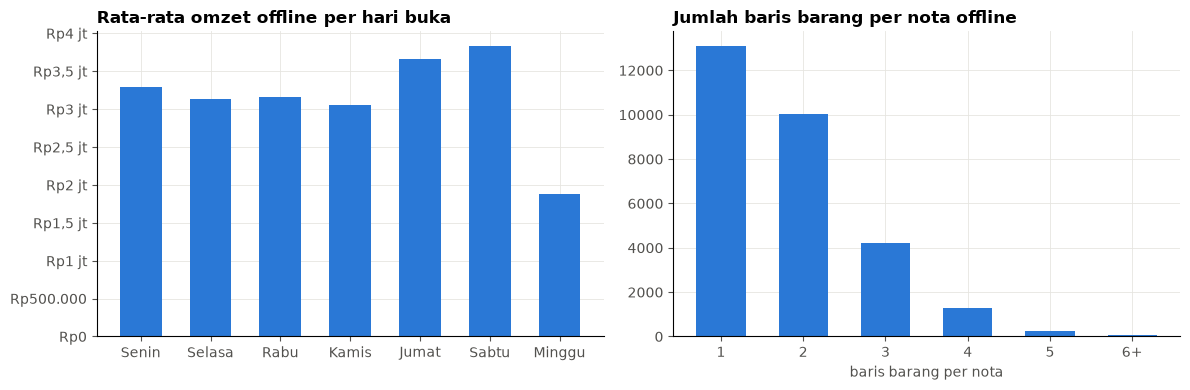

Tanggal dengan transaksi offline: 1030 dari 1096 hari kalender
Rata-rata baris per nota: 1.81 | median nilai nota: Rp76.000


In [7]:
off_items = items[items["kanal"] == "Offline"].copy()
off_items["hari"] = off_items["tanggal"].dt.day_name()
URUTAN_HARI = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
NAMA_HARI = dict(zip(URUTAN_HARI, ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]))
hari_aktif = off_items.groupby("tanggal")["hari"].first().value_counts() # berapa kali tiap hari muncul
omzet_hari = off_items.groupby("hari")["revenue"].sum() / hari_aktif # rata-rata omzet per hari buka
omzet_hari = omzet_hari.reindex(URUTAN_HARI).rename(index=NAMA_HARI)

trx_off = transactions[(transactions["kanal"] == "Offline") & ~transactions["order_no_generated"]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(omzet_hari.index, omzet_hari.values, color=WARNA_UTAMA, width=0.6)
ax1.yaxis.set_major_formatter(FuncFormatter(format_rupiah))
ax1.set_title("Rata-rata omzet offline per hari buka")
jumlah_item = trx_off["jumlah_item"].clip(upper=6).value_counts().sort_index()
ax2.bar(jumlah_item.index.astype(str).str.replace("6", "6+"), jumlah_item.values, color=WARNA_UTAMA, width=0.6)
ax2.set_title("Jumlah baris barang per nota offline")
ax2.set_xlabel("baris barang per nota")
plt.tight_layout()
plt.show()
print("Tanggal dengan transaksi offline:", off_items["tanggal"].nunique(), "dari", (AKHIR - off_items["tanggal"].min()).days + 1, "hari kalender")
print("Rata-rata baris per nota:", round(trx_off["jumlah_item"].mean(), 2), "| median nilai nota:", rupiah(trx_off["total_revenue"].median()))

**Insight:**
- Toko buka hampir setiap hari (1.030 dari 1.096 hari kalender).
- **Jumat dan Sabtu paling ramai** (rata-rata Rp3,7–3,8 juta per hari), sedangkan **Minggu paling sepi** (Rp1,9 juta, sekitar setengah hari biasa). Restok dan pemecahan sebaiknya dijadwalkan sebelum Jumat.
- Nota asli rata-rata berisi 1,8 baris barang; 45% nota hanya berisi satu barang. Median nilai nota Rp76.000.

### 2.4 Explore kategori dan produk

In [8]:
kat = (items.groupby("kategori").agg(sku_terjual=("sku", "nunique"), unit=("qty", "sum"), omzet=("revenue", "sum"))
       .join(products.groupby("kategori")["sku"].size().rename("sku_master")))
kat["porsi_omzet_%"] = (kat["omzet"] / kat["omzet"].sum() * 100).round(1)
kat = kat.sort_values("omzet", ascending=False)
display(kat.assign(omzet=kat["omzet"].map(rupiah)))
per_sku = items.groupby("sku")["revenue"].sum().sort_values(ascending=False)
kumulatif = per_sku.cumsum() / per_sku.sum()
print(f"SKU yang pernah terjual: {per_sku.size} dari {products['is_sellable'].sum()} SKU jual")
print(f"SKU yang menyumbang 80% omzet: {(kumulatif <= 0.8).sum() + 1} SKU ({((kumulatif <= 0.8).sum() + 1) / per_sku.size:.0%})")
print("SKU jual yang tidak pernah terjual:", sorted(set(products.loc[products["is_sellable"], "sku"]) - set(per_sku.index)))

,sku_terjual,unit,omzet,sku_master,porsi_omzet_%
kategori,,,,,
Insektisida,51,35460,Rp1.208.772.901,52,34.6
Pupuk,32,43013,Rp924.392.936,36,26.5
Herbisida,35,11189,Rp508.342.770,35,14.5
Fungisida,18,8533,Rp421.252.376,19,12.1
Nutrisi dan ZPT,28,13406,Rp337.139.779,29,9.6
Perlengkapan,19,4804,Rp94.862.678,19,2.7


SKU yang pernah terjual: 183 dari 186 SKU jual
SKU yang menyumbang 80% omzet: 57 SKU (31%)
SKU jual yang tidak pernah terjual: ['ANTILA500', 'ISADORA400', 'PAKETAG']


**Insight:**
- **Insektisida (34,6%) dan Pupuk (26,5%)** menyumbang lebih dari 60% omzet. Pupuk unggul dalam unit karena banyak dijual per kemasan kecil curah.
- Omzet terkonsentrasi: **57 SKU (31% dari SKU yang terjual) menyumbang 80% omzet**. SKU inilah yang paling penting akurasi stok dan forecast-nya.
- 183 dari 186 SKU jual pernah terjual. Tiga yang tidak pernah terjual: ANTILA500, ISADORA400, dan PAKETAG.

### 2.5 Explore harga online vs offline
Perbandingan harga satuan median per SKU di bulan yang sama, untuk SKU yang terjual di kedua kanal.

SKU yang terjual di kedua kanal pada bulan yang sama: 150
Rasio harga online / offline (median per SKU):
count    150.000
mean       1.190
std        0.039
min        1.121
10%        1.143
50%        1.184
90%        1.239
max        1.356
dtype: float64


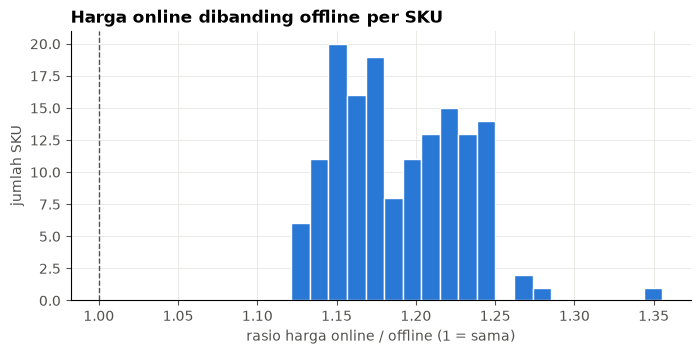

In [9]:
harga_bulan = items.groupby(["sku", "bulan", items["kanal"].eq("Offline").map({True: "offline", False: "online"})])["harga_satuan"].median().unstack()
harga_bulan = harga_bulan.dropna()
rasio = (harga_bulan["online"] / harga_bulan["offline"]).groupby("sku").median()
print("SKU yang terjual di kedua kanal pada bulan yang sama:", rasio.size)
print("Rasio harga online / offline (median per SKU):")
print(rasio.describe(percentiles=[0.1, 0.5, 0.9]).round(3))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rasio, bins=20, color=WARNA_UTAMA, edgecolor="white")
ax.axvline(1, color="#52514e", linewidth=1, linestyle="--")
ax.set_title("Harga online dibanding offline per SKU")
ax.set_xlabel("rasio harga online / offline (1 = sama)")
ax.set_ylabel("jumlah SKU")
plt.show()

**Insight:**
- Untuk 150 SKU yang dijual di kedua kanal, **harga online selalu lebih mahal**: median 18% di atas offline, paling rendah 12% dan paling tinggi 36%. Selisih ini menutup komisi dan biaya platform (lihat Q3).
- Karena itu omzet online tidak bisa dibandingkan langsung dengan offline per unit; perbandingan kanal di Q1 dan Q3 memakai omzet dan margin.

### 2.6 Explore `stock_movements` dan `stock_opname`

In [10]:
print(gerak.groupby("jenis")["qty"].agg(baris="size", total="sum").round(1).sort_values("baris", ascending=False))
stok_akhir = gerak.groupby("sku")["qty"].sum()
print("\nStok sistem per 31 Okt 2026: SKU berstok negatif =", (stok_akhir < 0).sum(), "| nol =", (stok_akhir == 0).sum())
print(stok_akhir[stok_akhir < 0].round(1).sort_values().to_dict())

              baris     total
jenis                        
SALE_OFFLINE  54893 -109954.0
SALE_ONLINE    5053   -6451.0
RESTOCK_IN     3551  103650.0
SPLIT_OUT       708  -14134.0
SPLIT_IN        708   26868.0
ADJUSTMENT      639   -1948.4
RETURN_IN       597    1132.0
OPENING         189    3773.0
ASSEMBLE_OUT    120    -150.0
DAMAGED_OUT      42     -79.0
ASSEMBLE_IN      41     166.0

Stok sistem per 31 Okt 2026: SKU berstok negatif = 8 | nol = 0
{'EXTRAPCKG': -345.0, 'DLMT': -95.0, 'EMKAPE500': -14.0, 'EM4C': -5.0, 'MEKARMAP1': -5.0, 'SAPPORO100': -5.0, 'RDPK': -4.0, 'PLYBG20': -2.0}


In [11]:
sel = opname.dropna(subset=["selisih"]).copy()
sel["selisih_persen"] = np.where(sel["stok_sistem"] > 0, sel["selisih"] / sel["stok_sistem"] * 100, np.nan)
print("Baris opname dengan stok sistem <= 0 (persen tidak bisa dihitung):", sel["selisih_persen"].isna().sum(), "dari", len(sel))
print(sel.groupby("tanggal").agg(sku=("sku", "size"), selisih_nol=("selisih", lambda s: (s.abs() < 1e-9).sum()),
                                 median_selisih_persen=("selisih_persen", "median")).round(1))

Baris opname dengan stok sistem <= 0 (persen tidak bisa dihitung): 67 dari 873
            sku  selisih_nol  median_selisih_persen
tanggal                                            
2024-02-29   94           24                  -11.2
2024-05-31   83           20                  -12.7
2024-08-31   54           24                    0.0
2024-11-30   56           20                    0.0
2025-02-28   74           25                    0.0
2025-05-31  106           28                  -11.1
2025-08-31   43            8                  -21.1
2025-11-30   74           17                  -16.7
2026-02-28   39           13                   -4.8
2026-05-31   45            6                  -33.3
2026-08-31  108           25                  -14.3
2026-10-31   97           24                  -12.5


**Insight:**
- Pergerakan stok didominasi penjualan offline (54.893 baris) dan restok (3.551 baris). Ada 639 penyesuaian opname (`ADJUSTMENT`).
- **8 SKU masih berstok negatif per 31 Okt 2026.** Yang terbesar `EXTRAPCKG` (extra kardus + bubblewrap, −345): SKU ini hanya muncul sebagai 345 penjualan online, tanpa stok awal, restok, maupun opname. Minusnya bukan kesalahan data, karena toko memang tidak melacak stok bahan kemasan (lihat aturan di bagian reorder). Sisanya (Dolomit −95, Emkape 500 g −14, dan lain-lain) mencatat barang keluar lebih banyak daripada yang tercatat masuk setelah opname terakhir.
- Selisih opname cenderung **negatif** (median per opname 0% sampai −33%): stok fisik lebih rendah daripada sistem. Sebagian berasal dari penjualan yang ditolak di wrangling (`penjualan_ambigu`) dan pemecahan yang tidak tercatat. Detailnya di Q6.

### 2.7 Explore ``marketplace_metrics``

In [12]:
m = metrik.copy()
m["konversi"] = np.where(m["klik"] > 0, m["pesanan"] / m["klik"], np.nan)
m["ctr"] = np.where(m["impresi"] > 0, m["klik"] / m["impresi"], np.nan)
print(m.groupby("kanal")[["impresi", "klik", "pesanan"]].sum().astype(int))
print(m.groupby("kanal")[["ctr", "konversi", "rating"]].median().round(4))
print("Rating kosong:", m["rating"].isna().sum(), "dari", len(m))

             impresi   klik  pesanan
kanal                               
Shopee       1963784  47702     1815
TikTok Shop  1427344  36468     1396
Tokopedia     955324  22747      695
                ctr  konversi  rating
kanal                                
Shopee       0.0291    0.0282     4.7
TikTok Shop  0.0296    0.0278     4.6
Tokopedia    0.0282    0.0000     4.7
Rating kosong: 1269 dari 4130


**Insight:**
- Shopee punya impresi, klik, dan pesanan tertinggi, disusul TikTok Shop, lalu Tokopedia.
- CTR (klik ÷ impresi) hampir sama di ketiga kanal (sekitar 2,9%). Median konversi bulanan per baris di Tokopedia **0**, karena banyak produk yang tidak mendapat pesanan sama sekali dalam sebulan; konversi Tokopedia lebih tepat dibaca dari total klik dan pesanan (Q10).
- 1.269 dari 4.130 baris belum punya rating, sehingga rating tidak dipakai sebagai ukuran utama.

### 2.8 Explore `penjualan_ambigu`
Baris ini tidak dihitung di Q1–Q6 (angka strict), tetapi dilihat sekali di sini supaya ukurannya diketahui.

In [13]:
print(ambigu.groupby("teks_asli").agg(baris=("qty", "size"), qty=("qty", "sum"), subtotal=("subtotal", "sum")))
print("Porsi dari omzet offline:", f"{ambigu['subtotal'].sum() / items.loc[items['kanal'] == 'Offline', 'revenue'].sum():.2%}")

                 baris    qty   subtotal
teks_asli                               
Polybag Tanaman    182  318.0  6661500.0
Pupuk Amazing      148  255.0  4939500.0
ROUNDUP 486 SL       1   10.0    88500.0
Porsi dari omzet offline: 0.36%


**Insight:**
- Penjualan yang ditolak karena nama ambigu hanya **0,36% omzet offline**, hampir semuanya `Polybag Tanaman` dan `Pupuk Amazing`. Angka Q1–Q6 di bawah memakai data strict. Karena nilainya kecil, penjualan ini juga **tidak** dimasukkan ke target forecast di notebook 03; dampaknya (forecast AGT/AGB dan polybag sedikit lebih rendah) dicatat sebagai keterbatasan.

## 3. Visualization & Explanatory Analysis

### Pertanyaan 1 (Q1)
**Berapa omzet (Rp) dan jumlah barang terjual tiap bulan, totalnya dan per kanal (Offline, Shopee, Tokopedia, TikTok Shop), dari Nov 2023 sampai Okt 2026, dan naik atau turun berapa persen omzet Okt 2026 dibanding Sep 2026?**

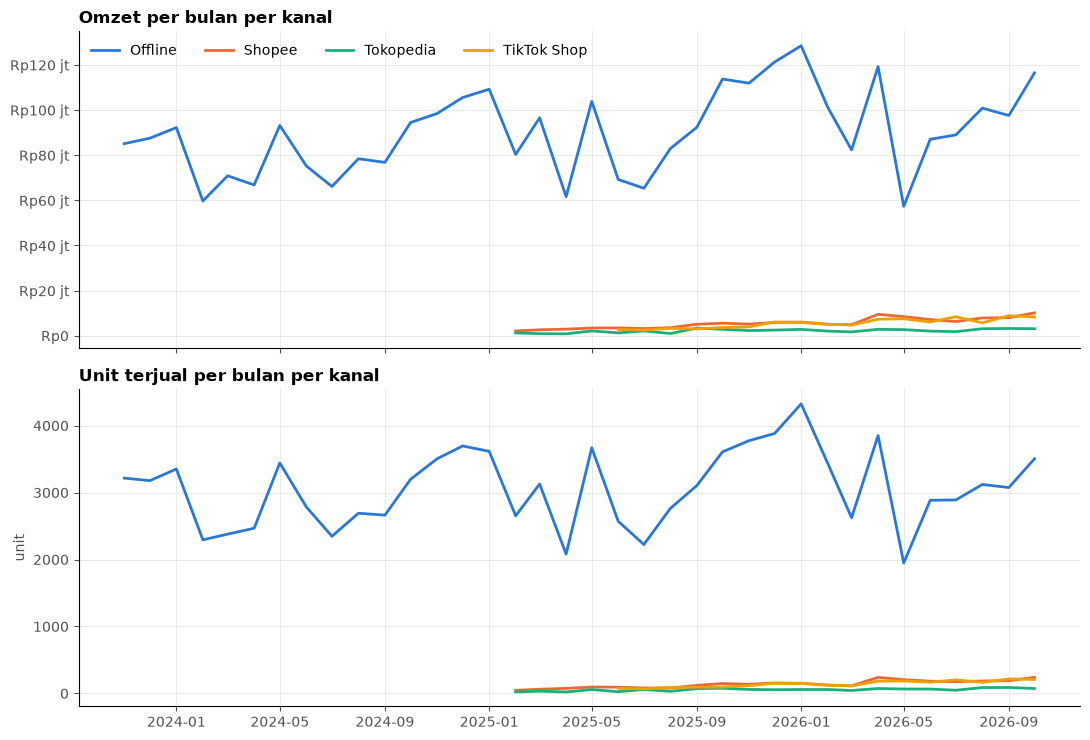

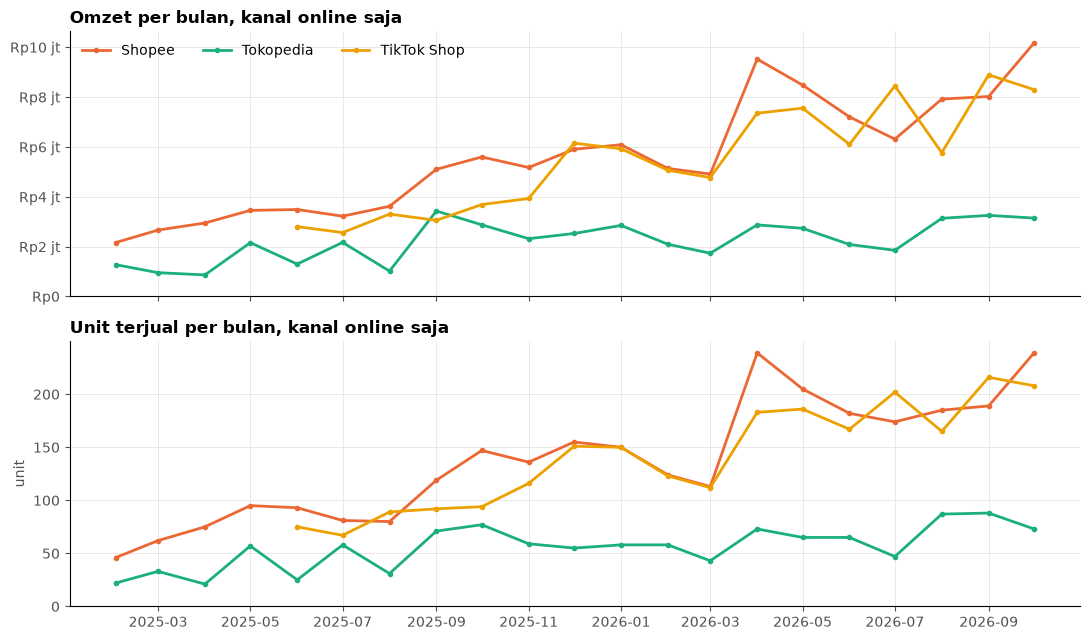

In [15]:
omzet_kanal = items.pivot_table(index="bulan", columns="kanal", values="revenue", aggfunc="sum", fill_value=0)[KANAL_BAKU]
unit_kanal = items.pivot_table(index="bulan", columns="kanal", values="qty", aggfunc="sum", fill_value=0)[KANAL_BAKU]
omzet_kanal["Total"] = omzet_kanal.sum(axis=1)
unit_kanal["Total"] = unit_kanal.sum(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for kanal in KANAL_BAKU:
    aktif = omzet_kanal[kanal] > 0                                  # garis kanal online dimulai saat kanal dibuka
    ax1.plot(omzet_kanal.index[aktif].to_timestamp(), omzet_kanal.loc[aktif, kanal], color=WARNA_KANAL[kanal], label=kanal)
    ax2.plot(unit_kanal.index[aktif].to_timestamp(), unit_kanal.loc[aktif, kanal], color=WARNA_KANAL[kanal], label=kanal)
ax1.yaxis.set_major_formatter(FuncFormatter(format_rupiah))
ax1.set_title("Omzet per bulan per kanal")
ax2.set_title("Unit terjual per bulan per kanal")
ax2.set_ylabel("unit")
ax1.legend(loc="upper left", ncol=4)
plt.tight_layout()
plt.show()

# Kanal online saja, supaya trennya terlihat (skala Offline jauh lebih besar)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for kanal in ["Shopee", "Tokopedia", "TikTok Shop"]:
    aktif = omzet_kanal[kanal] > 0                                  # mulai dari bulan kanal itu dibuka
    x = omzet_kanal.index[aktif].to_timestamp()
    ax1.plot(x, omzet_kanal.loc[aktif, kanal], color=WARNA_KANAL[kanal], marker="o", markersize=3, label=kanal)
    ax2.plot(x, unit_kanal.loc[aktif, kanal], color=WARNA_KANAL[kanal], marker="o", markersize=3, label=kanal)
ax1.yaxis.set_major_formatter(FuncFormatter(format_rupiah))
ax1.set_title("Omzet per bulan, kanal online saja")
ax2.set_title("Unit terjual per bulan, kanal online saja")
ax2.set_ylabel("unit")
ax1.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)
ax1.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

In [16]:
# Tabel bulanan (Rp juta dan unit) supaya angka bisa dibaca langsung
tabel_q1 = pd.concat({"omzet (Rp juta)": (omzet_kanal / 1e6).round(1), "unit": unit_kanal}, axis=1)
tabel_q1.tail(12)

omzet (Rp juta)                                        unit                                   
kanal           Offline Shopee Tokopedia TikTok Shop  Total Offline Shopee Tokopedia TikTok Shop Total
bulan                                                                                                 
2025-11           111.9    5.2       2.3         3.9  123.3    3775    136        59         116  4086
2025-12           121.2    5.9       2.5         6.1  135.8    3883    155        55         151  4244
2026-01           128.4    6.1       2.8         5.9  143.3    4325    150        58         150  4683
2026-02           101.3    5.1       2.1         5.1  113.5    3439    124        58         123  3744
2026-03            82.3    4.9       1.7         4.8   93.7    2624    113        43         112  2892
2026-04           119.2    9.5       2.9         7.3  139.0    3852    239        73         183  4347
2026-05            57.3    8.5       2.7         7.5   76.1    1948    205        65         186  2404
2026-06            87.0    7.2       2.1         6.1  102.4    2885    182        65         167  3299
2026-07            89.0    6.3       1.8         8.4  105.5    2890    174        47         202  3313
2026-08           100.8    7.9       3.1         5.8  117.6    3121    185        87         165  3558
2026-09            97.6    8.0       3.2         8.9  117.7    3075    189        88         216  3568
2026-10           116.4   10.2       3.1         8.3  138.0    3505    239        73         208  4025

In [17]:
def perubahan(df, bulan_ini="2026-10", bulan_lalu="2026-09"):
    ini, lalu = df.loc[pd.Period(bulan_ini)], df.loc[pd.Period(bulan_lalu)]
    return pd.DataFrame({"Sep 2026": lalu, "Okt 2026": ini, "perubahan_%": ((ini - lalu) / lalu * 100).round(1)})

print("Omzet:")
display(perubahan(omzet_kanal).assign(**{"Sep 2026": lambda d: d["Sep 2026"].map(rupiah), "Okt 2026": lambda d: d["Okt 2026"].map(rupiah)}))
print("Unit:")
display(perubahan(unit_kanal))
print("Total 36 bulan: omzet", rupiah(omzet_kanal["Total"].sum()), "| unit", int(unit_kanal["Total"].sum()))

Omzet:


,Sep 2026,Okt 2026,perubahan_%
kanal,,,
Offline,Rp97.563.000,Rp116.411.000,19.3
Shopee,Rp8.016.564,Rp10.164.928,26.8
Tokopedia,Rp3.249.622,Rp3.140.242,-3.4
TikTok Shop,Rp8.886.783,Rp8.291.531,-6.7
Total,Rp117.715.969,Rp138.007.701,17.2


Unit:


,Sep 2026,Okt 2026,perubahan_%
kanal,,,
Offline,3075,3505,14.0
Shopee,189,239,26.5
Tokopedia,88,73,-17.0
TikTok Shop,216,208,-3.7
Total,3568,4025,12.8


Total 36 bulan: omzet Rp3.494.763.439 | unit 116405


**Insight:**
- Selama Nov 2023 sampai Okt 2026, total omzet **Rp3,49 miliar** dan **116.405 unit**. Offline tetap tulang punggung toko; ketiga marketplace bersama-sama hanya sekitar 13% unit per bulan.
- **Okt 2026 vs Sep 2026: omzet total naik 17,2%** (Rp117,7 juta → Rp138,0 juta) dan **unit naik 12,8%** (3.568 → 4.025).
  - Offline: omzet **+19,3%**, unit **+14,0%**.
  - Shopee: omzet **+26,8%**, unit **+26,5%**. Ini kenaikan tertinggi dan rekor bulanan Shopee (Rp10,2 juta).
  - Tokopedia: omzet **−3,4%**, unit **−17,0%**.
  - TikTok Shop: omzet **−6,7%**, unit **−3,7%**.
- Okt 2026 juga 9,7% lebih tinggi daripada Okt 2025, jadi kenaikannya bukan sekadar pulih dari bulan sebelumnya.
- **Unit online bergerak searah dengan omzetnya.** Shopee dan TikTok Shop melonjak di Apr 2026 (Shopee 113 → 239 unit, TikTok Shop 112 → 183 unit dari Mar ke Apr) dan bertahan di 165–240 unit per kanal sampai Okt 2026. Tokopedia stabil di kisaran 21–88 unit per bulan (median 58).
- **Kanal yang perlu didorong:** Shopee tumbuh paling cepat dan paling besar di antara kanal online. Tokopedia paling kecil dan turun di Okt 2026.

### Pertanyaan 2 (Q2)
**Dalam 12 bulan terakhir (Nov 2025 sampai Okt 2026), 10 produk apa yang paling laku (dari omzet dan jumlah terjual), dan bagaimana urutan 6 kategori produk berdasarkan omzet beserta persen sumbangannya terhadap total omzet?**

In [18]:
MULAI_12 = pd.Timestamp("2025-11-01")
items_12 = items[items["tanggal"] >= MULAI_12]
total_omzet_12 = items_12["revenue"].sum()
produk_12 = items_12.groupby(["sku", "nama", "kategori"]).agg(omzet=("revenue", "sum"), unit=("qty", "sum")).reset_index()
produk_12["kontribusi_omzet_%"] = (produk_12["omzet"] / total_omzet_12 * 100).round(2)
top_omzet = produk_12.nlargest(10, "omzet").reset_index(drop=True)
top_unit = produk_12.nlargest(10, "unit").reset_index(drop=True)
print("Total omzet 12 bulan:", rupiah(total_omzet_12))
print(f"Kontribusi 10 produk teratas (omzet): {top_omzet['kontribusi_omzet_%'].sum():.1f}%")
display(top_omzet.assign(omzet=top_omzet["omzet"].map(rupiah)))
display(top_unit.assign(omzet=top_unit["omzet"].map(rupiah)))

Total omzet 12 bulan: Rp1.406.019.712
Kontribusi 10 produk teratas (omzet): 35.6%


,sku,nama,kategori,omzet,unit,kontribusi_omzet_%
0,MKP1,MKP Pak Tani,Pupuk,Rp89.442.677,1302,6.36
1,EMKAPE1,Emkape Maxxi Agri,Pupuk,Rp68.335.387,1105,4.86
2,METAZEB1,Metazeb 80 WP,Fungisida,Rp53.587.544,323,3.81
3,KCL,KCL Curah,Pupuk,Rp52.686.000,4025,3.75
4,BLSTC,Balistic 50 SC,Insektisida,Rp44.733.375,782,3.18
5,SAPPORO100,Sapporo 52 EC,Insektisida,Rp44.137.969,579,3.14
6,RDPB,Roundup 486 SL,Herbisida,Rp44.093.204,455,3.14
7,WINDER100,Winder 100 EC,Insektisida,Rp36.257.967,724,2.58
8,SUPEREL100,Superel 480 SL,Herbisida,Rp34.473.908,1396,2.45
9,TROBOS100,Trobos 200 SL,Nutrisi dan ZPT,Rp32.692.445,1715,2.33


,sku,nama,kategori,omzet,unit,kontribusi_omzet_%
0,KCL,KCL Curah,Pupuk,Rp52.686.000,4025,3.75
1,DLMT,Kapur Dolomite,Pupuk,Rp12.542.000,3593,0.89
2,UREA,Urea Curah,Pupuk,Rp27.103.500,1903,1.93
3,TROBOS100,Trobos 200 SL,Nutrisi dan ZPT,Rp32.692.445,1715,2.33
4,ETREKKCL,E-Trek anti rayap,Insektisida,Rp20.060.036,1654,1.43
5,SUPEREL100,Superel 480 SL,Herbisida,Rp34.473.908,1396,2.45
6,MKP1,MKP Pak Tani,Pupuk,Rp89.442.677,1302,6.36
7,KOVINPLUS,Kovin Plus 80P,Insektisida,Rp4.714.945,1164,0.34
8,EMKAPE1,Emkape Maxxi Agri,Pupuk,Rp68.335.387,1105,4.86
9,DANGKE100,Dangke 40 WP,Insektisida,Rp29.071.360,907,2.07


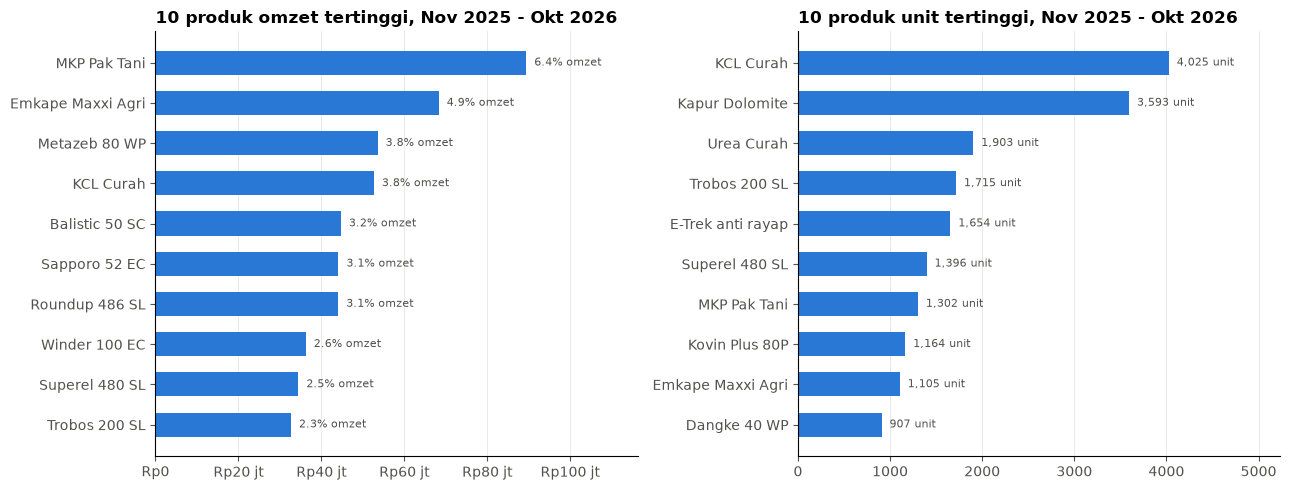

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for ax, data, kolom, judul in [(ax1, top_omzet, "omzet", "10 produk omzet tertinggi"), (ax2, top_unit, "unit", "10 produk unit tertinggi")]:
    d = data.iloc[::-1]
    ax.barh(d["nama"].str.slice(0, 28), d[kolom], color=WARNA_UTAMA, height=0.6)
    ax.set_title(judul + ", Nov 2025 - Okt 2026")
    ax.grid(axis="y", visible=False)
    for y, (nilai, persen) in enumerate(zip(d[kolom], d["kontribusi_omzet_%"])):
        teks = f"{persen:.1f}% omzet" if kolom == "omzet" else f"{nilai:,.0f} unit"
        ax.text(nilai, y, "  " + teks, va="center", fontsize=8, color="#52514e")
    ax.set_xlim(0, d[kolom].max() * 1.3)
ax1.xaxis.set_major_formatter(FuncFormatter(format_rupiah))
plt.tight_layout()
plt.show()

Jumlah kategori: 6


,omzet,unit,sku,kontribusi_omzet_%,kontribusi_unit_%
kategori,,,,,
Insektisida,Rp490.211.243,13859,51,34.9,31.4
Pupuk,Rp364.207.319,15575,31,25.9,35.3
Herbisida,Rp206.823.024,4381,32,14.7,9.9
Fungisida,Rp173.417.391,3314,18,12.3,7.5
Nutrisi dan ZPT,Rp133.196.313,5079,27,9.5,11.5
Perlengkapan,Rp38.164.422,1955,18,2.7,4.4


Urutan kategori menurut unit: ['Pupuk', 'Insektisida', 'Nutrisi dan ZPT', 'Herbisida', 'Fungisida', 'Perlengkapan']


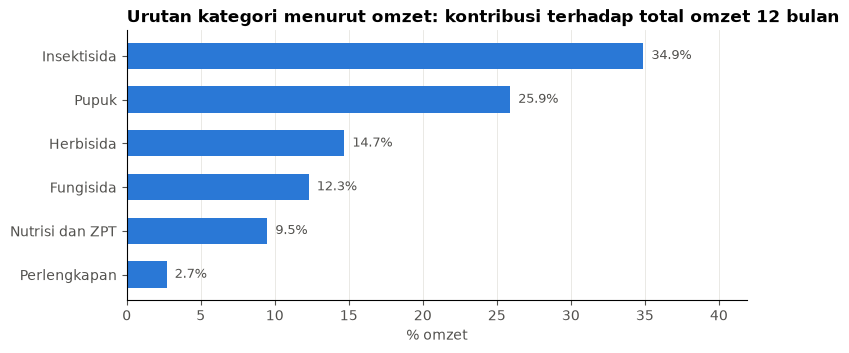

In [20]:
kategori_12 = items_12.groupby("kategori").agg(omzet=("revenue", "sum"), unit=("qty", "sum"), sku=("sku", "nunique"))
kategori_12["kontribusi_omzet_%"] = (kategori_12["omzet"] / total_omzet_12 * 100).round(1)
kategori_12["kontribusi_unit_%"] = (kategori_12["unit"] / kategori_12["unit"].sum() * 100).round(1)
urutan_kategori = kategori_12.sort_values("omzet", ascending=False)
print("Jumlah kategori:", len(urutan_kategori))
display(urutan_kategori.assign(omzet=urutan_kategori["omzet"].map(rupiah)))
print("Urutan kategori menurut unit:", kategori_12.sort_values("unit", ascending=False).index.tolist())

fig, ax = plt.subplots(figsize=(8, 3.5))
d = urutan_kategori.iloc[::-1]
ax.barh(d.index, d["kontribusi_omzet_%"], color=WARNA_UTAMA, height=0.6)
for y, v in enumerate(d["kontribusi_omzet_%"]):
    ax.text(v, y, f"  {v:.1f}%", va="center", fontsize=9, color="#52514e")
ax.set_title("Urutan kategori menurut omzet: kontribusi terhadap total omzet 12 bulan")
ax.set_xlabel("% omzet")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, d["kontribusi_omzet_%"].max() * 1.2)
plt.show()

**Insight:**
- Total omzet 12 bulan terakhir (Nov 2025 – Okt 2026) **Rp1,41 miliar**.
- **10 produk omzet tertinggi menyumbang 35,6% omzet.** Urutan teratas: **MKP Pak Tani (6,4%)**, Emkape Maxxi Agri (4,9%), Metazeb 80 WP (3,8%), KCL Curah (3,8%), dan Balistic 50 SC (3,2%).
- **10 produk unit tertinggi** didominasi pupuk curah yang murah per kemasan: **KCL Curah (4.025 unit)**, Kapur Dolomite (3.593), Urea Curah (1.903), lalu Trobos 200 SL (1.715). Kapur Dolomite laku hampir 3.600 unit tetapi hanya menyumbang 0,9% omzet.
- Produk yang masuk **kedua daftar** (omzet dan unit tinggi): MKP Pak Tani, Emkape Maxxi Agri, KCL Curah, Trobos 200 SL, dan Superel 480 SL. Stok kelima produk ini perlu diprioritaskan.
- **Urutan 6 kategori menurut omzet:** Insektisida (34,9%), Pupuk (25,9%), Herbisida (14,7%), Fungisida (12,3%), Nutrisi dan ZPT (9,5%), dan Perlengkapan (2,7%). Menurut unit, Pupuk menjadi yang pertama (35,3% unit).

### Pertanyaan 3 (Q3)
**Dalam 12 bulan terakhir, berapa persen keuntungan bersih dari omzet untuk tiap kategori dan tiap kanal, setelah dikurangi modal barang (HPP) dan biaya platform?**

Cara menghitung:
- **Online**: `laba_bersih` di `online_item_financials` sudah dikurangi HPP (harga kulakan), komisi platform, komisi affiliator, biaya program ongkir, dan biaya packing.
- **Offline**: laba = subtotal − qty × HPP per unit. Offline tidak punya biaya platform. HPP per unit diambil dari **harga beli di `product_price_history`** (median harga restok per SKU per bulan, per satuan stok):
  - Dipakai harga beli **terakhir sampai bulan transaksi**, karena toko tidak membeli setiap SKU setiap bulan.
  - **Kemasan hasil pemecahan** (mis. Urea Curah 0,5 kg) tidak pernah dibeli; HPP-nya = harga beli induk per kg × isi kemasan dalam kg.
  - **Paket** = jumlah HPP komponennya (`bundle_components`).
  - Jika belum ada harga beli sama sekali, dipakai HPP master.
- Margin bersih = laba bersih / omzet × 100.

In [21]:
fin_12 = finansial[finansial["order_date"] >= MULAI_12].copy()
fin_12["biaya_platform"] = fin_12["komisi_platform"] + fin_12["komisi_affiliator"] + fin_12["biaya_program_ongkir"] + fin_12["biaya_packing"]

# HPP per unit dari harga beli (product_price_history), diisi ke depan sampai ada harga beli baru
bundle = baca("bundle_components")
semua_bulan = pd.period_range(riwayat_harga["bulan"].min(), AKHIR, freq="M")
harga_beli = (riwayat_harga[riwayat_harga["jenis_harga"] == "beli"]
              .assign(bulan=lambda d: d["bulan"].dt.to_period("M"))
              .pivot_table(index="bulan", columns="sku", values="harga")
              .reindex(semua_bulan).ffill())

def hpp_dari_beli(sku, bulan):
    if pd.notna(info.at[sku, "sku_induk"]):                          # kemasan hasil pemecahan
        induk = info.at[sku, "sku_induk"]
        per_kg = harga_beli.at[bulan, induk] if induk in harga_beli else np.nan
        return per_kg * info.at[sku, "faktor_ke_induk"], "harga beli induk"
    if info.at[sku, "is_bundle"]:                                     # paket = jumlah komponen
        komp = bundle[bundle["sku_paket"] == sku]
        nilai = [hpp_dari_beli(k, bulan)[0] * q for k, q in zip(komp["sku_komponen"], komp["qty_komponen_per_paket"])]
        return (sum(nilai) if all(pd.notna(nilai)) else np.nan), "komponen paket"
    return (harga_beli.at[bulan, sku] if sku in harga_beli else np.nan), "harga beli SKU"

off_12 = items_12[items_12["kanal"] == "Offline"].copy()
pasangan = off_12[["sku", "bulan"]].drop_duplicates()
hasil = [hpp_dari_beli(s, b) for s, b in zip(pasangan["sku"], pasangan["bulan"])]
pasangan["hpp_unit"] = [h for h, _ in hasil]
pasangan["sumber_hpp"] = [sumber for _, sumber in hasil]
off_12 = off_12.merge(pasangan, on=["sku", "bulan"], how="left")
off_12.loc[off_12["hpp_unit"].isna(), "sumber_hpp"] = "HPP master"
off_12["hpp_unit"] = off_12["hpp_unit"].fillna(off_12["sku"].map(info["hpp"]))
off_12["hpp_total"] = off_12["qty"] * off_12["hpp_unit"]
off_12["laba_bersih"] = off_12["revenue"] - off_12["hpp_total"]
print("Sumber HPP offline (baris):", off_12["sumber_hpp"].value_counts().to_dict())
print("Baris offline tanpa HPP sama sekali:", off_12["hpp_unit"].isna().sum())

laba = pd.concat([
    off_12[["kanal", "kategori", "revenue", "hpp_total", "laba_bersih"]].assign(biaya_platform=0.0),
    fin_12.assign(kategori=fin_12["sku"].map(info["kategori"]))
          .rename(columns={"netto": "revenue"})[["kanal", "kategori", "revenue", "hpp_total", "biaya_platform", "laba_bersih"]],
], ignore_index=True)
print("Cek: selisih omzet dengan transaction_items 12 bulan:", rupiah(laba["revenue"].sum() - total_omzet_12))

Sumber HPP offline (baris): {'harga beli SKU': 16845, 'harga beli induk': 2772, 'HPP master': 53, 'komponen paket': 39}
Baris offline tanpa HPP sama sekali: 0
Cek: selisih omzet dengan transaction_items 12 bulan: Rp0


In [22]:
def tabel_margin(df, kolom):
    t = df.groupby(kolom)[["revenue", "hpp_total", "biaya_platform", "laba_bersih"]].sum()
    t["margin_bersih_%"] = (t["laba_bersih"] / t["revenue"] * 100).round(1)
    t["hpp_%"] = (t["hpp_total"] / t["revenue"] * 100).round(1)
    t["biaya_platform_%"] = (t["biaya_platform"] / t["revenue"] * 100).round(1)
    return t.sort_values("margin_bersih_%", ascending=False)

margin_kanal = tabel_margin(laba, "kanal")
margin_kategori = tabel_margin(laba, "kategori")
jumlah_kk = laba.pivot_table(index="kategori", columns="kanal", values=["laba_bersih", "revenue"], aggfunc="sum")
margin_kategori_kanal = (jumlah_kk["laba_bersih"] / jumlah_kk["revenue"] * 100).round(1)[KANAL_BAKU]
def tampil_rupiah(df):
    kolom_rp = ["revenue", "hpp_total", "biaya_platform", "laba_bersih"]
    return df.assign(**{k: df[k].map(rupiah) for k in kolom_rp})

display(tampil_rupiah(margin_kanal))
display(tampil_rupiah(margin_kategori))
print("Margin bersih % per kategori x kanal:")
margin_kategori_kanal

,revenue,hpp_total,biaya_platform,laba_bersih,margin_bersih_%,hpp_%,biaya_platform_%
kanal,,,,,,,
Offline,Rp1.212.487.500,Rp829.742.403,Rp0,Rp382.745.097,31.6,68.4,0.0
Tokopedia,Rp30.553.990,Rp19.874.500,Rp2.795.749,Rp7.883.741,25.8,65.0,9.2
Shopee,Rp84.782.576,Rp54.971.050,Rp9.779.296,Rp20.032.230,23.6,64.8,11.5
TikTok Shop,Rp78.195.646,Rp50.740.250,Rp18.541.390,Rp8.914.006,11.4,64.9,23.7


,revenue,hpp_total,biaya_platform,laba_bersih,margin_bersih_%,hpp_%,biaya_platform_%
kategori,,,,,,,
Pupuk,Rp364.207.319,Rp243.777.053,Rp5.490.218,Rp114.940.048,31.6,66.9,1.5
Nutrisi dan ZPT,Rp133.196.313,Rp88.581.850,Rp3.171.935,Rp41.442.528,31.1,66.5,2.4
Insektisida,Rp490.211.243,Rp327.207.650,Rp12.055.059,Rp150.948.534,30.8,66.7,2.5
Fungisida,Rp173.417.391,Rp121.603.350,Rp3.864.323,Rp47.949.718,27.6,70.1,2.2
Herbisida,Rp206.823.024,Rp146.888.600,Rp5.454.677,Rp54.479.747,26.3,71.0,2.6
Perlengkapan,Rp38.164.422,Rp27.269.700,Rp1.080.223,Rp9.814.499,25.7,71.5,2.8


Margin bersih % per kategori x kanal:


kanal,Offline,Shopee,Tokopedia,TikTok Shop
kategori,,,,
Fungisida,29.1,23.0,25.9,11.0
Herbisida,28.1,22.6,24.5,9.7
Insektisida,32.7,25.5,26.6,11.3
Nutrisi dan ZPT,32.8,24.6,27.4,14.5
Perlengkapan,26.8,24.4,24.9,12.9
Pupuk,33.1,20.9,24.3,11.7


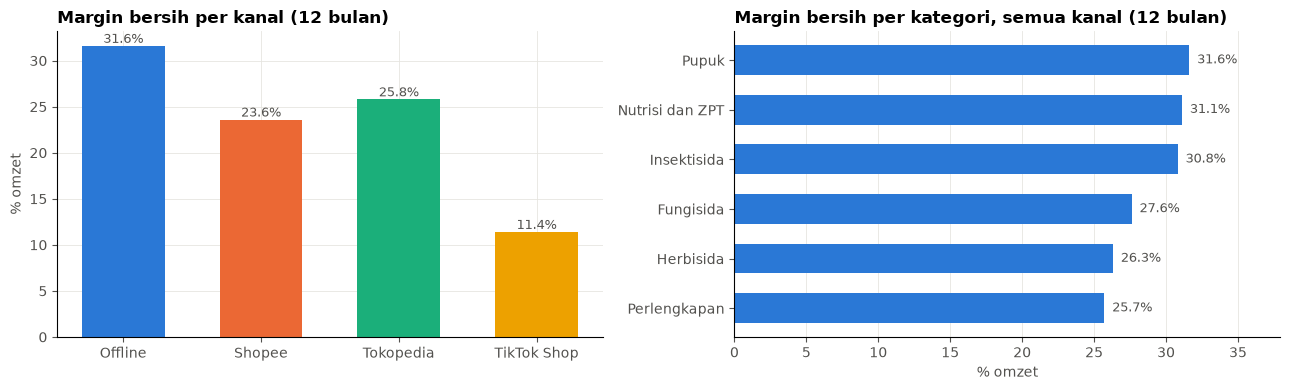

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
d = margin_kanal.reindex(KANAL_BAKU)
ax1.bar(d.index, d["margin_bersih_%"], color=[WARNA_KANAL[k] for k in d.index], width=0.6)
for x, v in enumerate(d["margin_bersih_%"]):
    ax1.text(x, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color="#52514e")
ax1.set_title("Margin bersih per kanal (12 bulan)")
ax1.set_ylabel("% omzet")
d = margin_kategori.sort_values("margin_bersih_%")
ax2.barh(d.index, d["margin_bersih_%"], color=WARNA_UTAMA, height=0.6)
for y, v in enumerate(d["margin_bersih_%"]):
    ax2.text(v, y, f"  {v:.1f}%", va="center", fontsize=9, color="#52514e")
ax2.set_title("Margin bersih per kategori, semua kanal (12 bulan)")
ax2.set_xlabel("% omzet")
ax2.grid(axis="y", visible=False)
ax2.set_xlim(0, d["margin_bersih_%"].max() * 1.2)
plt.tight_layout()
plt.show()

**Insight:**
- **Margin bersih per kanal (12 bulan):** Offline **31,6%**, Tokopedia **25,8%**, Shopee **23,6%**, TikTok Shop **11,4%**.
- HPP hampir sama di semua kanal (65–68% omzet), karena harga online sudah dinaikkan sekitar 18%. Yang membedakan adalah **biaya platform**: Tokopedia 9,2%, Shopee 11,5%, dan **TikTok Shop 23,7%** omzet. Pola ini konsisten di semua kategori: margin TikTok Shop hanya 9,7–14,5%.
- **Margin bersih per kategori (semua kanal):** Pupuk **31,6%**, Nutrisi dan ZPT **31,1%**, Insektisida **30,8%**, Fungisida **27,6%**, Herbisida **26,3%**, Perlengkapan **25,7%**.
- **Produk dan kanal yang layak didorong:** Pupuk, Nutrisi dan ZPT, dan Insektisida memberi margin tertinggi sekaligus omzet terbesar. Di online, Shopee memberi laba bersih terbesar (Rp20,0 juta) dengan margin wajar. TikTok Shop omzetnya hampir menyamai Shopee tetapi labanya kurang dari setengah, jadi biaya programnya perlu ditinjau sebelum didorong.
- *Catatan:* 99,7% baris offline memakai harga beli dari `product_price_history` (langsung, lewat harga induk per kg, atau lewat komponen paket). Hanya 53 baris memakai HPP master karena SKU-nya belum pernah tercatat direstok dengan harga.

### Aturan stok (`reorder_settings`)
Q4 dan Q5 membutuhkan **titik pesan ulang** dan **batas memecah** per SKU. Angka ini tidak ada di data mentah, jadi di sini akan menggunakan aturan yang sederhana dan mudah dijelaskan ke UMKM:

| Istilah | Rumus | Keterangan |
|---|---|---|
| Rata-rata harian | unit terjual 90 hari terakhir (3 Agu – 31 Okt 2026) ÷ 90 | Semua kanal. Untuk komponen paket, ditambah pemakaian untuk merakit paket. Untuk SKU induk, ditambah pemakaian untuk kemasan hasil pecahannya |
| Stok pengaman | **2 unit** untuk SKU yang stoknya dihitung per unit; **1 karung (50 kg)** untuk induk karung 50 kg | Batas bawah tetap yang mudah diingat UMKM. Untuk induk karung, UMKM tidak menyebut angka khusus, jadi dipakai asumsi tim: satu karung cadangan. Kemasan pabrik 1 kg (EMKAPE1, KANITRAT1) stoknya dihitung per unit, jadi ikut 2 unit |
| **Titik pesan ulang** | rata-rata harian × lead time supplier + stok pengaman | Untuk SKU yang dibeli dari supplier dan SKU induk. Perlu dipesan ulang jika stok < titik pesan ulang |
| **Batas memecah** | 2 unit | Untuk kemasan hasil pemecahan. Perlu dipecah jika stok kemasan ≤ 2 unit dan stok induk cukup untuk minimal satu kemasan |
| **Batas merakit** | 2 unit | Untuk 5 paket (informasi tambahan; Q4 hanya meminta memecah dan pesan ulang) |

- **Lead time hanya diisi untuk SKU yang dipesan ke supplier** (jenis beli dan induk). Lead time diambil dari `suppliers` lewat `supplier_utama`; SKU yang dipesan tetapi belum punya supplier memakai lead time **terlama (7 hari)** supaya aman, ditandai `lead_time_asumsi`. Kemasan pecahan (diisi dari karung induk), paket (dirakit sendiri), dan `EXTRAPCKG` tidak dipesan, jadi lead time-nya kosong.
- SKU yang tidak terjual dalam 90 hari punya rata-rata 0. Karena tidak ada permintaan, SKU ini tidak dimasukkan ke daftar pesan ulang atau pecah, dan diberi status **"tidak laku 90 hari"**. SKU ini tetap ditampilkan supaya pemilik toko bisa melihat barang yang menumpuk.
- SKU yang **tidak pernah punya pergerakan masuk** (saldo awal, restok, retur, pecah, rakit) **dan tidak pernah di-opname** dianggap **bukan barang stok**. Di data ini hanya `EXTRAPCKG` (extra kardus + bubblewrap untuk pesanan online): toko memang tidak melacak stok bahan kemasan, jadi stok sistemnya yang minus bukan kesalahan data. SKU ini tetap dihitung di penjualan dan keuntungan (Q1–Q3), tetapi tidak diberi aturan stok dan dikeluarkan dari Q4, Q5, dan Q8.
- Ini adalah **aturan stok awal**. Nantinya di `03_modeling.ipynb`, jumlah yang dipesan (Q8) dihitung dari hasil forecast Q7.

In [24]:
bundle = baca("bundle_components")
STOK_PENGAMAN_UNIT = 2                                             # SKU yang stoknya dihitung per unit
STOK_PENGAMAN_KARUNG = 50                                          # induk karung 50 kg (satuan stok kg) = 1 karung
LEAD_TIME_ASUMSI = int(suppliers["lead_time_hari"].max())
mulai_90 = AKHIR - pd.Timedelta(days=89)                           # 3 Agu - 31 Okt 2026 = 90 hari
jual_90 = items[items["tanggal"] >= mulai_90].groupby("sku")["qty"].sum()
print("Periode 90 hari:", mulai_90.date(), "-", AKHIR.date())

rs = products[["sku", "nama", "kategori", "satuan_stok", "is_sellable", "is_bundle", "is_induk_pemecahan",
               "sku_induk", "faktor_ke_induk", "supplier_utama"]].set_index("sku")
pernah_masuk = gerak.loc[gerak["qty"] > 0, "sku"].unique()
rs["dicatat_stok"] = rs.index.isin(pernah_masuk) | rs.index.isin(opname["sku"])
rs["jenis_stok"] = np.select([~rs["dicatat_stok"], rs["is_bundle"], rs["sku_induk"].notna(), rs["is_induk_pemecahan"]],
                             ["bukan stok", "paket", "kemasan pecahan", "induk"], default="beli")
print("SKU bukan barang stok:", rs.index[~rs["dicatat_stok"]].tolist(),
      "| terjual 90 hari:", jual_90.reindex(rs.index[~rs["dicatat_stok"]]).fillna(0).to_dict())
rs["harian_jual"] = (jual_90 / 90).reindex(rs.index).fillna(0)

# Pemakaian komponen untuk merakit paket: penjualan paket x qty komponen per paket
pakai_paket = (bundle.assign(pakai=bundle["sku_paket"].map(rs["harian_jual"]) * bundle["qty_komponen_per_paket"])
               .groupby("sku_komponen")["pakai"].sum())
# Pemakaian induk untuk kemasan pecahan: penjualan kemasan x faktor_ke_induk (kg atau unit induk)
anak = rs[rs["jenis_stok"] == "kemasan pecahan"]
pakai_induk = (anak["harian_jual"] * anak["faktor_ke_induk"]).groupby(anak["sku_induk"]).sum()
rs["rata_harian_90h"] = (rs["harian_jual"] + pakai_paket.reindex(rs.index).fillna(0)
                         + pakai_induk.reindex(rs.index).fillna(0)).round(3)

dipesan = rs["jenis_stok"].isin(["beli", "induk"])                  # hanya SKU ini yang dipesan ke supplier
rs["lead_time_hari"] = rs["supplier_utama"].map(suppliers.set_index("supplier_code")["lead_time_hari"]).where(dipesan)
rs["lead_time_asumsi"] = rs["lead_time_hari"].isna() & dipesan
rs["lead_time_hari"] = rs["lead_time_hari"].where(~rs["lead_time_asumsi"], LEAD_TIME_ASUMSI).astype("Int64")
rs["stok_pengaman"] = np.select([rs["jenis_stok"] == "bukan stok", rs["satuan_stok"] == "kg"],
                                [np.nan, STOK_PENGAMAN_KARUNG], default=STOK_PENGAMAN_UNIT)
rs["titik_pesan_ulang"] = np.where(dipesan, (rs["rata_harian_90h"] * rs["lead_time_hari"] + rs["stok_pengaman"]).round(1), np.nan)
rs["batas_memecah"] = np.where(rs["jenis_stok"] == "kemasan pecahan", STOK_PENGAMAN_UNIT, np.nan)
rs["batas_merakit"] = np.where(rs["jenis_stok"] == "paket", STOK_PENGAMAN_UNIT, np.nan)
rs["catatan"] = np.select([rs["jenis_stok"] == "bukan stok", rs["rata_harian_90h"] == 0],
                          ["bukan barang stok (stok bahan kemasan tidak dilacak)", "tidak laku 90 hari"], default="")
print(rs["jenis_stok"].value_counts().to_dict())
print("SKU dipesan ke supplier:", dipesan.sum(), "| lead time dari supplier:", (dipesan & ~rs["lead_time_asumsi"]).sum(),
      "| lead time asumsi 7 hari:", rs["lead_time_asumsi"].sum(), "| tidak dipesan (lead time kosong):", (~dipesan).sum())
rs.loc[["UREA50KG", "UREA", "EMKAPE1", "KANITRAT1", "EMKAPE500", "PAKETBUAH250", "AGT"],
       ["jenis_stok", "satuan_stok", "harian_jual", "rata_harian_90h", "lead_time_hari", "stok_pengaman", "titik_pesan_ulang", "batas_memecah"]]

Periode 90 hari: 2026-08-03 - 2026-10-31
SKU bukan barang stok: ['EXTRAPCKG'] | terjual 90 hari: {'EXTRAPCKG': 83}
{'beli': 172, 'kemasan pecahan': 6, 'induk': 6, 'paket': 5, 'bukan stok': 1}
SKU dipesan ke supplier: 178 | lead time dari supplier: 161 | lead time asumsi 7 hari: 17 | tidak dipesan (lead time kosong): 12


,jenis_stok,satuan_stok,harian_jual,rata_harian_90h,lead_time_hari,stok_pengaman,titik_pesan_ulang,batas_memecah
sku,,,,,,,,
UREA50KG,induk,kg,0.000000,2.478,3,50.0,57.4,NaN
UREA,kemasan pecahan,unit,4.955556,4.956,<NA>,2.0,NaN,2.0
EMKAPE1,induk,unit,2.688889,3.131,5,2.0,17.7,NaN
KANITRAT1,induk,unit,0.188889,0.200,5,2.0,3.0,NaN
EMKAPE500,kemasan pecahan,unit,0.855556,0.856,<NA>,2.0,NaN,2.0
PAKETBUAH250,paket,unit,0.055556,0.056,<NA>,2.0,NaN,NaN
AGT,beli,unit,0.922222,0.922,4,2.0,5.7,NaN


In [25]:
kolom_rs = ["nama", "kategori", "jenis_stok", "satuan_stok", "sku_induk", "faktor_ke_induk", "rata_harian_90h",
            "supplier_utama", "lead_time_hari", "lead_time_asumsi", "stok_pengaman", "titik_pesan_ulang",
            "batas_memecah", "batas_merakit", "catatan"]
reorder_settings = rs[kolom_rs].reset_index()
reorder_settings.insert(len(reorder_settings.columns), "periode_dasar", f"{mulai_90.date()} s.d. {AKHIR.date()}")
reorder_settings.to_csv(PROCESSED / "reorder_settings.csv", index=False)
print("reorder_settings disimpan:", reorder_settings.shape)

reorder_settings disimpan: (190, 17)


**Insight:**
- `reorder_settings` berisi 190 SKU: 172 dibeli dari supplier, 6 SKU induk, 6 kemasan pecahan, 5 paket, dan 1 bukan barang stok (`EXTRAPCKG`). `EXTRAPCKG` tidak diberi aturan stok apa pun dan dikeluarkan dari Q4, Q5, dan Q8.
- Contoh **Urea**: kemasan Urea Curah terjual sekitar 5 kemasan per hari dan perlu dipecah jika stoknya tinggal 2 kemasan atau kurang. Karung induk `UREA50KG` dipakai 2,5 kg per hari; dengan lead time 3 hari dan stok pengaman satu karung (50 kg), titik pesan ulangnya **57,4 kg**.
- Kemasan pabrik 1 kg (EMKAPE1, KANITRAT1) stoknya dihitung per unit, jadi stok pengamannya 2 unit seperti SKU lain (titik pesan ulang EMKAPE1 17,7 unit).
- Untuk SKU per unit, stok pengamannya kecil (2 unit), sehingga titik pesan ulang terutama ditentukan oleh rata-rata harian × lead time.
- **178 SKU dipesan ke supplier** (172 jenis beli dan 6 induk): 161 memakai lead time dari supplier utamanya, dan 17 yang belum punya supplier memakai aturan pengganti 7 hari. Kemasan pecahan, paket, dan `EXTRAPCKG` tidak dipesan, jadi lead time-nya kosong.
- Tabel disimpan ke `data/processed/reorder_settings.csv` dan akan dipakai lagi untuk Q8.

### Pertanyaan 4 (Q4)
**Per 31 Okt 2026, SKU mana saja yang perlu segera dipecah dari karung atau kemasan induk (stok kemasan menipis tetapi induknya masih ada), dan SKU mana yang perlu dipesan ulang ke supplier (stok di bawah titik pesan ulang)?**

In [26]:
stok = gerak[gerak["tanggal"] <= AKHIR].groupby("sku")["qty"].sum().reindex(rs.index).fillna(0).round(2)
rs["stok_31okt"] = stok
rs["stok_induk"] = rs["sku_induk"].map(stok)

perlu_memecah = (rs["jenis_stok"] == "kemasan pecahan") & (rs["stok_31okt"] <= rs["batas_memecah"])
induk_ada = rs["stok_induk"] >= rs["faktor_ke_induk"]                      # cukup untuk minimal satu kemasan
rs["status"] = "aman"
rs.loc[perlu_memecah & induk_ada, "status"] = "perlu memecah"
rs.loc[perlu_memecah & ~induk_ada, "status"] = "perlu memecah, induk habis"
rs.loc[dipesan & (rs["stok_31okt"] < rs["titik_pesan_ulang"]), "status"] = "perlu dipesan ulang"
rs.loc[(rs["jenis_stok"] == "paket") & (rs["stok_31okt"] < rs["batas_merakit"]), "status"] = "perlu merakit"
rs.loc[rs["rata_harian_90h"] == 0, "status"] = "tidak laku 90 hari"           # tanpa permintaan, tidak dipesan/dipecah
rs.loc[rs["jenis_stok"] == "bukan stok", "status"] = "bukan barang stok"
rs["stok_negatif"] = rs["stok_31okt"] < 0

print(rs.groupby(["jenis_stok", "status"]).size().unstack(fill_value=0))
print("\nJumlah SKU perlu memecah:", (rs["status"] == "perlu memecah").sum(),
      "| perlu memecah tetapi induk habis:", (rs["status"] == "perlu memecah, induk habis").sum(),
      "| perlu dipesan ulang:", (rs["status"] == "perlu dipesan ulang").sum())

status           aman  bukan barang stok  perlu dipesan ulang  perlu memecah  tidak laku 90 hari
jenis_stok                                                                                      
beli              138                  0                   17              0                  17
bukan stok          0                  1                    0              0                   0
induk               5                  0                    1              0                   0
kemasan pecahan     4                  0                    0              2                   0
paket               3                  0                    0              0                   2

Jumlah SKU perlu memecah: 2 | perlu memecah tetapi induk habis: 0 | perlu dipesan ulang: 18


In [27]:
kolom_tampil = ["nama", "jenis_stok", "satuan_stok", "stok_31okt", "rata_harian_90h", "lead_time_hari", "titik_pesan_ulang",
                "batas_memecah", "sku_induk", "stok_induk", "stok_negatif"]
print("SKU perlu memecah:")
display(rs.loc[rs["status"].str.startswith("perlu memecah"), kolom_tampil + ["status"]])
print("SKU perlu dipesan ulang (diurutkan dari kekurangan terbesar terhadap titik pesan ulang):")
restok = rs[rs["status"] == "perlu dipesan ulang"].assign(kurang=lambda d: d["titik_pesan_ulang"] - d["stok_31okt"])
display(restok.sort_values("kurang", ascending=False)[kolom_tampil + ["kurang"]])

SKU perlu memecah:


,nama,jenis_stok,satuan_stok,stok_31okt,rata_harian_90h,lead_time_hari,titik_pesan_ulang,batas_memecah,sku_induk,stok_induk,stok_negatif,status
sku,,,,,,,,,,,,
DLMT,Kapur Dolomite,kemasan pecahan,unit,-95.0,7.167,<NA>,NaN,2.0,DLMT50KG,100.0,True,perlu memecah
EMKAPE500,Emkape Maxxi Agri,kemasan pecahan,unit,-14.0,0.856,<NA>,NaN,2.0,EMKAPE1,107.0,True,perlu memecah


SKU perlu dipesan ulang (diurutkan dari kekurangan terbesar terhadap titik pesan ulang):


,nama,jenis_stok,satuan_stok,stok_31okt,rata_harian_90h,lead_time_hari,titik_pesan_ulang,batas_memecah,sku_induk,stok_induk,stok_negatif,kurang
sku,,,,,,,,,,,,
SAPPORO100,Sapporo 52 EC,beli,unit,-5.0,1.511,3,6.5,NaN,NaN,NaN,True,11.5
MEKARMAP1,MekarMAP,beli,unit,-5.0,0.578,5,4.9,NaN,NaN,NaN,True,9.9
PLYBG35,Polybag Tanaman 35x35,beli,unit,1.0,1.167,7,10.2,NaN,NaN,NaN,False,9.2
EM4C,EM4 Peternakan,beli,unit,-5.0,0.156,4,2.6,NaN,NaN,NaN,True,7.6
RDPK,Roundup 486 SL,beli,unit,-4.0,0.200,5,3.0,NaN,NaN,NaN,True,7.0
PLYBG20,Polybag Tanaman 20x20,beli,unit,-2.0,0.133,7,2.9,NaN,NaN,NaN,True,4.9
FRTPHS50KG,Fertiphos Pak Tani (karung 50 kg),induk,kg,50.0,1.067,3,53.2,NaN,NaN,NaN,False,3.2
BROADPLUS40,BroadPlus 77 WP,beli,unit,1.0,0.444,5,4.2,NaN,NaN,NaN,False,3.2
EM4K,EM4 Pertanian,beli,unit,1.0,0.522,4,4.1,NaN,NaN,NaN,False,3.1


In [28]:
# SKU tanpa penjualan 90 hari tetap ditampilkan, supaya barang yang menumpuk terlihat
terakhir_terjual = items.groupby("sku")["tanggal"].max()
musim_lalu = items[items["tanggal"].between(mulai_90 - pd.DateOffset(years=1), AKHIR - pd.DateOffset(years=1))]["sku"].unique()
tidak_laku = rs[rs["status"] == "tidak laku 90 hari"].copy()
tidak_laku["terakhir_terjual"] = tidak_laku.index.map(terakhir_terjual).date
tidak_laku["terjual_periode_sama_tahun_lalu"] = tidak_laku.index.isin(musim_lalu)
print("SKU tidak laku 90 hari:", len(tidak_laku), "| tidak pernah terjual:", tidak_laku["terakhir_terjual"].isna().sum(),
      "| stok terkecil:", tidak_laku["stok_31okt"].min())
tidak_laku.sort_values("terakhir_terjual", na_position="first")[["nama", "jenis_stok", "stok_31okt", "terakhir_terjual", "terjual_periode_sama_tahun_lalu"]]

SKU tidak laku 90 hari: 19 | tidak pernah terjual: 3 | stok terkecil: 3.0


,nama,jenis_stok,stok_31okt,terakhir_terjual,terjual_periode_sama_tahun_lalu
sku,,,,,
ISADORA400,Isadora 75 SP,beli,8.0,NaT,False
PAKETAG,Paket AG Buah dan Tumbuh,paket,5.0,NaT,False
ANTILA500,Antila 80 WP,beli,9.0,NaT,False
PLYBG25,Polybag Tanaman 25x25,beli,3.0,2024-05-08,False
EM4B,EM4 Limbah / Toilet,beli,7.0,2025-09-22,True
GEMPUR1,Gempur 480 SL,beli,7.0,2025-09-28,True
KALINET500,Kalinet Kalium Cair,beli,10.0,2025-10-03,True
GLUBEST1L,Glubest 200 SL,beli,5.0,2025-10-29,True
LINDOMIN400,Lindomin 865 SL,beli,7.0,2025-10-30,True


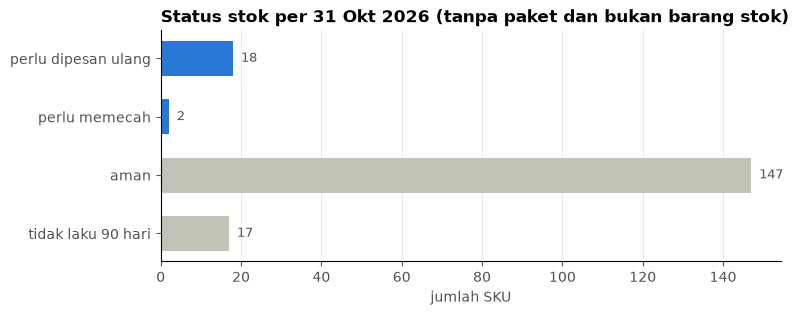

In [29]:
hitung = rs[~rs["jenis_stok"].isin(["paket", "bukan stok"])]["status"].value_counts()
urutan = ["perlu dipesan ulang", "perlu memecah", "perlu memecah, induk habis", "aman", "tidak laku 90 hari"]
hitung = hitung.reindex([u for u in urutan if u in hitung.index])
fig, ax = plt.subplots(figsize=(8, 3))
warna = [WARNA_UTAMA if s.startswith("perlu") else WARNA_REDUP for s in hitung.index]
ax.barh(hitung.index[::-1], hitung.values[::-1], color=warna[::-1], height=0.6)
for y, v in enumerate(hitung.values[::-1]):
    ax.text(v, y, f"  {v}", va="center", fontsize=9, color="#52514e")
ax.set_title("Status stok per 31 Okt 2026 (tanpa paket dan bukan barang stok)")
ax.set_xlabel("jumlah SKU")
ax.grid(axis="y", visible=False)
plt.show()

**Insight:**
- Per 31 Okt 2026, **2 SKU perlu dipecah** dan **18 SKU perlu dipesan ulang**.
- **Perlu dipecah:** **Kapur Dolomite (DLMT)** dan **Emkape Maxxi Agri 500 g (EMKAPE500)**. Stok induknya masih ada (Dolomit 100 kg, Emkape 1 kg 107 unit), jadi cukup dipecah tanpa membeli. Stok sistem kedua kemasan ini negatif (−95 dan −14), tanda bahwa pemecahan sebelumnya tidak selalu dicatat. Saat memecah, admin perlu mencatat pemecahannya.
- **Perlu dipesan ulang (18 SKU):** kekurangan terbesar terhadap titik pesan ulang ada di **Sapporo 52 EC, MekarMAP, Polybag 35x35, EM4 Peternakan, dan Roundup 486 SL ukuran kecil (RDPK)**. Lima SKU stok sistemnya negatif (Sapporo, MekarMAP, EM4 Peternakan, RDPK, Polybag 20x20), jadi stok fisiknya perlu dicek dulu sebelum memesan.
- Satu induk ikut masuk daftar: **Fertiphos karung (FRTPHS50KG)** stoknya tinggal 50 kg, tepat satu karung cadangan, sedangkan titik pesan ulangnya 53,2 kg. Lima induk lain masih aman (mis. UREA50KG 149,4 kg vs titik 57,4 kg).
- Tiga ukuran polybag (15, 20, 35) masuk daftar pesan ulang. Penjualan polybag yang ditolak di wrangling tidak mengurangi stok sistem, jadi stok fisik polybag kemungkinan **lebih rendah lagi**.
- **19 SKU tidak laku 90 hari** (sejak 3 Agu 2026) tetap ditampilkan dengan status "tidak laku 90 hari". Semuanya punya stok minimal 3 unit, jadi tanpa aturan ini pun tidak ada yang masuk daftar pesan ulang; aturan ini menjadi pengaman untuk data berikutnya. Isinya beragam:
  - 3 SKU tidak pernah terjual sama sekali: ANTILA500, ISADORA400, dan PAKETAG.
  - Beberapa sudah lama tidak laku, mis. Polybag 25x25 (terakhir Mei 2024). Untuk polybag, sebagian penjualan mungkin tersembunyi di `penjualan_ambigu` karena kasir hanya menulis "polybag tanaman".
  - 7 SKU terjual pada periode yang sama tahun lalu (mis. King Tonik, Ambition, Glubest 200 SL), jadi kemungkinan musiman dan bisa laku lagi.
  - Pemilik toko bisa memakai daftar ini untuk melihat barang yang menumpuk.

### Pertanyaan 5 (Q5)
**Per 31 Okt 2026, stok tiap SKU cukup untuk berapa hari lagi jika penjualannya sama dengan rata-rata 90 hari terakhir, dan berapa SKU yang stoknya akan habis sebelum barang pesanan baru datang (lebih pendek dari lead time supplier)?**

- **SKU aktif** = SKU yang terjual (atau dipakai untuk merakit/memecah) dalam 90 hari terakhir.
- Hari cukup = stok ÷ rata-rata harian.
- Ada tiga kelompok SKU yang hari cukupnya **tidak dihitung**, masing-masing dengan alasan yang berbeda:
  1. **Stok sistem negatif** (bermasalah sementara): hari cukup tidak bermakna sampai stok fisiknya dicek.
  2. **Bukan barang yang dilacak stoknya** (`EXTRAPCKG`): stoknya memang tidak pernah dicatat.
  3. **Tidak ada penjualan 90 hari**: rata-rata hariannya 0, sehingga stok ÷ 0 tidak bisa dihitung. SKU ini diberi label, tidak diisi angka tak hingga atau dibiarkan kosong.
- Perbandingan dengan lead time hanya berlaku untuk SKU yang **dibeli dari supplier** (jenis `beli` dan `induk`). Kemasan pecahan dan paket diisi ulang di toko, bukan dipesan.

In [30]:
rs["hari_cukup_tidak_dihitung"] = np.select(
    [rs["jenis_stok"] == "bukan stok", rs["stok_negatif"], rs["rata_harian_90h"] == 0],
    ["bukan barang yang dilacak stoknya", "stok sistem negatif, cek fisik dulu", "tidak ada penjualan 90 hari"], default="")
tidak_dihitung = rs[rs["hari_cukup_tidak_dihitung"] != ""]
print("SKU yang hari cukupnya tidak dihitung:", tidak_dihitung["hari_cukup_tidak_dihitung"].value_counts().to_dict())
print("Dikecualikan karena stok minus (stok negatif + bukan barang stok):",
      tidak_dihitung["hari_cukup_tidak_dihitung"].isin(["bukan barang yang dilacak stoknya", "stok sistem negatif, cek fisik dulu"]).sum())
display(tidak_dihitung[tidak_dihitung["hari_cukup_tidak_dihitung"] != "tidak ada penjualan 90 hari"]
        [["nama", "jenis_stok", "stok_31okt", "rata_harian_90h", "hari_cukup_tidak_dihitung"]])
aktif = rs[rs["hari_cukup_tidak_dihitung"] == ""].copy()
aktif["hari_cukup"] = (aktif["stok_31okt"] / aktif["rata_harian_90h"]).round(1)
beli_aktif = aktif[aktif["jenis_stok"].isin(["beli", "induk"])].copy()
beli_aktif["kurang_dari_lead_time"] = beli_aktif["hari_cukup"] < beli_aktif["lead_time_hari"]
print("SKU aktif:", len(aktif), "| dibeli dari supplier:", len(beli_aktif))
print("Hari cukup (semua SKU aktif):", aktif["hari_cukup"].describe(percentiles=[0.25, 0.5, 0.75]).round(1).to_dict())
print("SKU aktif dengan stok cukup lebih dari 120 hari:", (aktif["hari_cukup"] > 120).sum())
print("SKU dibeli yang hari cukupnya < lead time:", beli_aktif["kurang_dari_lead_time"].sum(),
      f"({beli_aktif['kurang_dari_lead_time'].mean():.0%})")
display(beli_aktif[beli_aktif["kurang_dari_lead_time"]].sort_values("hari_cukup")
        [["nama", "jenis_stok", "satuan_stok", "stok_31okt", "rata_harian_90h", "hari_cukup", "lead_time_hari", "lead_time_asumsi"]])

SKU yang hari cukupnya tidak dihitung: {'tidak ada penjualan 90 hari': 19, 'stok sistem negatif, cek fisik dulu': 7, 'bukan barang yang dilacak stoknya': 1}
Dikecualikan karena stok minus (stok negatif + bukan barang stok): 8


,nama,jenis_stok,stok_31okt,rata_harian_90h,hari_cukup_tidak_dihitung
sku,,,,,
DLMT,Kapur Dolomite,kemasan pecahan,-95.0,7.167,"stok sistem negatif, cek fisik dulu"
SAPPORO100,Sapporo 52 EC,beli,-5.0,1.511,"stok sistem negatif, cek fisik dulu"
MEKARMAP1,MekarMAP,beli,-5.0,0.578,"stok sistem negatif, cek fisik dulu"
EM4C,EM4 Peternakan,beli,-5.0,0.156,"stok sistem negatif, cek fisik dulu"
EMKAPE500,Emkape Maxxi Agri,kemasan pecahan,-14.0,0.856,"stok sistem negatif, cek fisik dulu"
EXTRAPCKG,extra kardus + bubblewrap,bukan stok,-345.0,0.922,bukan barang yang dilacak stoknya
PLYBG20,Polybag Tanaman 20x20,beli,-2.0,0.133,"stok sistem negatif, cek fisik dulu"
RDPK,Roundup 486 SL,beli,-4.0,0.200,"stok sistem negatif, cek fisik dulu"


SKU aktif: 163 | dibeli dari supplier: 156
Hari cukup (semua SKU aktif): {'count': 163.0, 'mean': 81.8, 'std': 147.2, 'min': 0.9, '25%': 21.9, '50%': 37.5, '75%': 62.8, 'max': 1090.9}
SKU aktif dengan stok cukup lebih dari 120 hari: 22
SKU dibeli yang hari cukupnya < lead time: 4 (3%)


,nama,jenis_stok,satuan_stok,stok_31okt,rata_harian_90h,hari_cukup,lead_time_hari,lead_time_asumsi
sku,,,,,,,,
PLYBG35,Polybag Tanaman 35x35,beli,unit,1.0,1.167,0.9,7,False
EM4K,EM4 Pertanian,beli,unit,1.0,0.522,1.9,4,False
RGNTB,Regent 50 EC,beli,unit,2.0,0.922,2.2,3,False
BROADPLUS40,BroadPlus 77 WP,beli,unit,1.0,0.444,2.3,5,False


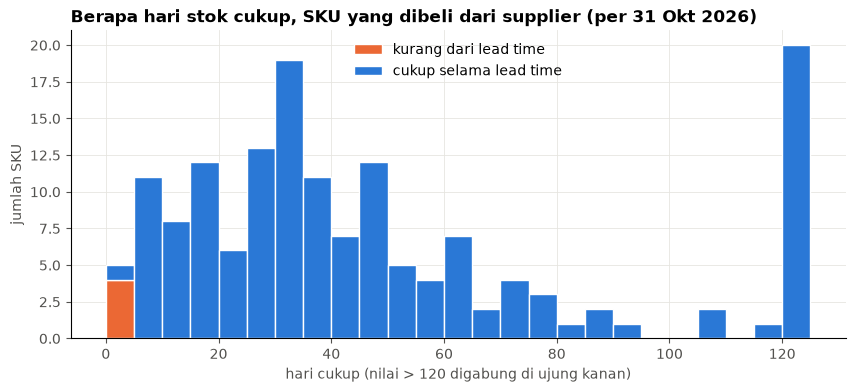

Hari cukup per jenis stok (median): {'beli': 38.5, 'induk': 32.35, 'kemasan pecahan': 24.2, 'paket': 89.3}


In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
batas_tampil = 120
d = beli_aktif["hari_cukup"].clip(upper=batas_tampil)
ax.hist([d[beli_aktif["kurang_dari_lead_time"]], d[~beli_aktif["kurang_dari_lead_time"]]], bins=np.arange(0, batas_tampil + 6, 5),
        stacked=True, color=[WARNA_KANAL["Shopee"], WARNA_UTAMA], label=["kurang dari lead time", "cukup selama lead time"],
        edgecolor="white")
ax.set_title("Berapa hari stok cukup, SKU yang dibeli dari supplier (per 31 Okt 2026)")
ax.set_xlabel(f"hari cukup (nilai > {batas_tampil} digabung di ujung kanan)")
ax.set_ylabel("jumlah SKU")
ax.legend()
plt.show()
print("Hari cukup per jenis stok (median):", aktif.groupby("jenis_stok")["hari_cukup"].median().to_dict())

**Insight:**
- Hari cukup **tidak dihitung** untuk 27 SKU, dengan alasan berbeda:
  - **7 SKU berstok sistem negatif** (bermasalah sementara): Kapur Dolomite, Emkape 500 g, Sapporo 52 EC, MekarMAP, EM4 Peternakan, Polybag 20x20, dan Roundup 486 SL (RDPK). Stok fisiknya perlu dicek dulu.
  - **`EXTRAPCKG`** (memang bukan barang yang dilacak stoknya). Bersama 7 SKU di atas, totalnya 8 SKU berstok minus yang dikecualikan.
  - **19 SKU tanpa penjualan 90 hari**: rata-rata hariannya 0, jadi diberi label "tidak ada penjualan 90 hari", bukan angka tak hingga.
- Dari **163 SKU aktif** sisanya, median stok **cukup 37,5 hari** (kuartil 22–63 hari).
- Dari 156 SKU yang dibeli dari supplier, **4 SKU (3%) stoknya habis sebelum pesanan baru datang** (hari cukup < lead time): **Polybag 35x35 (0,9 hari), EM4 Pertanian (1,9 hari), Regent 50 EC (2,2 hari), dan BroadPlus 77 WP (2,3 hari)**. Keempatnya harus dipesan paling dulu, bersama SKU berstok negatif yang ternyata habis setelah dicek fisik.
- Di sisi lain, **22 SKU** stoknya cukup lebih dari 120 hari. Modal yang tertahan di SKU ini bisa dipindahkan ke SKU yang laris.

### Pertanyaan 6 (Q6)
**Dari 12 opname (Feb 2024 sampai Okt 2026; opname 1 Nov 2023 adalah stok awal), seberapa besar biasanya selisih antara stok di sistem dan stok fisik (median, dalam persen), dan berapa SKU yang selisihnya lebih dari 10 persen pada opname 31 Okt 2026?**

- Selisih persen = (stok fisik − stok sistem) ÷ stok sistem × 100. Mediannya dihitung dari **nilai mutlak** (besar selisih, tanpa melihat arah).
- Opname pertama (1 Nov 2023) adalah stok awal, jadi tidak punya selisih. Selisih di setiap opname adalah selisih **sejak opname sebelumnya** (K12 di notebook 01).
- Stok sistem ≤ 0 tidak bisa dijadikan pembagi: nol membuat persen tidak terdefinisi, dan pembagi negatif membalik tanda persennya. Karena itu kedua bagian pertanyaan diperlakukan berbeda:
  1. **Median persen selisih** dihitung hanya dari SKU yang stok sistemnya positif, karena hanya di situ persennya bermakna.
  2. **Jumlah SKU dengan selisih > 10%** menghitung semua SKU. SKU abnormal (stok sistem nol atau minus) yang barangnya ada secara fisik pasti selisihnya jauh di atas 10%, jadi otomatis ikut dihitung. SKU abnormal juga ditampilkan dalam tabel tersendiri.

In [32]:
q6 = opname.dropna(subset=["selisih"]).copy()
q6["selisih_persen"] = np.where(q6["stok_sistem"] > 0, q6["selisih"] / q6["stok_sistem"] * 100, np.nan)
q6["selisih_persen_mutlak"] = q6["selisih_persen"].abs()
per_opname = q6.groupby("tanggal").agg(
    sku=("sku", "size"), sistem_le_0=("selisih_persen", lambda s: s.isna().sum()),
    median_selisih_persen_mutlak=("selisih_persen_mutlak", "median"), median_selisih_persen=("selisih_persen", "median"),
    sku_di_atas_10=("selisih_persen_mutlak", lambda s: (s > 10).sum())).round(2)
display(per_opname)
print("Median selisih persen mutlak, semua 12 opname:", round(q6["selisih_persen_mutlak"].median(), 2), "%")

,sku,sistem_le_0,median_selisih_persen_mutlak,median_selisih_persen,sku_di_atas_10
tanggal,,,,,
2024-02-29,94,4,14.29,-11.20,58
2024-05-31,83,7,16.09,-12.66,46
2024-08-31,54,2,8.00,0.00,24
2024-11-30,56,3,8.40,0.00,23
2025-02-28,74,11,11.11,0.00,33
2025-05-31,106,7,18.18,-11.11,58
2025-08-31,43,3,26.79,-21.11,28
2025-11-30,74,7,16.67,-16.67,42
2026-02-28,39,4,9.43,-4.76,17


Median selisih persen mutlak, semua 12 opname: 16.23 %


In [33]:
okt = q6[q6["tanggal"] == AKHIR].copy()
okt["nama"] = okt["sku"].map(info["nama"])
okt["abnormal"] = okt["stok_sistem"] <= 0
okt["di_atas_10"] = (okt["selisih_persen_mutlak"] > 10) | (okt["abnormal"] & (okt["stok_fisik"] != okt["stok_sistem"]))
normal_10 = (okt["di_atas_10"] & ~okt["abnormal"]).sum()
abnormal_10 = (okt["di_atas_10"] & okt["abnormal"]).sum()
print("Opname 31 Okt 2026:", len(okt), "SKU | selisih > 10%:", okt["di_atas_10"].sum(),
      f"= {normal_10} SKU normal + {abnormal_10} SKU abnormal (stok sistem <= 0)")
print("SKU abnormal:")
display(okt[okt["abnormal"]][["sku", "nama", "stok_sistem", "stok_fisik", "selisih"]])
okt["sku_penjualan_ambigu"] = okt["sku"].isin(["AGT", "AGB"] + [f"PLYBG{n}" for n in range(15, 55, 5)])
display(okt[okt["di_atas_10"] & ~okt["abnormal"]].sort_values("selisih_persen_mutlak", ascending=False)
        [["sku", "nama", "stok_sistem", "stok_fisik", "selisih", "selisih_persen", "sku_penjualan_ambigu"]])

Opname 31 Okt 2026: 97 SKU | selisih > 10%: 64 = 58 SKU normal + 6 SKU abnormal (stok sistem <= 0)
SKU abnormal:


,sku,nama,stok_sistem,stok_fisik,selisih
975,BRVXN,Bravoxone 276 SL,-3.0,3.0,6.0
982,DCSK,Decis 25 EC,0.0,9.0,9.0
992,FSTN100,Fostin 610 EC,-7.0,3.0,10.0
1007,KCL,KCL Curah,-227.0,105.0,332.0
1042,RGNTB,Regent 50 EC,-3.0,2.0,5.0
1057,UREA,Urea Curah,-31.0,54.0,85.0


,sku,nama,stok_sistem,stok_fisik,selisih,selisih_persen,sku_penjualan_ambigu
968,ANTRCL500,Antracol 70 WP,7.0,26.0,19.0,271.428571,False
1032,PAKETGDSL,Paket Gandasil B dan D,2.0,7.0,5.0,250.000000,False
971,BESTAR1L,Bestar 200 SL,2.0,6.0,4.0,200.000000,False
970,ATNK,Atonik 6.0 L,3.0,9.0,6.0,200.000000,False
1037,PLYBG35,Polybag Tanaman 35x35,30.0,1.0,-29.0,-96.666667,True
972,BIOCALSIUM1,Bio Calsium,24.0,4.0,-20.0,-83.333333,False
1038,PLYBG50,Polybag Tanaman 50x50,34.0,9.0,-25.0,-73.529412,True
1059,WINDER100,Winder 100 EC,60.0,17.0,-43.0,-71.666667,False
1052,SUMO80,Sumo 50 EC,41.0,13.0,-28.0,-68.292683,False
1020,MAXXIGROB500,Maxxigro B,30.0,10.0,-20.0,-66.666667,False


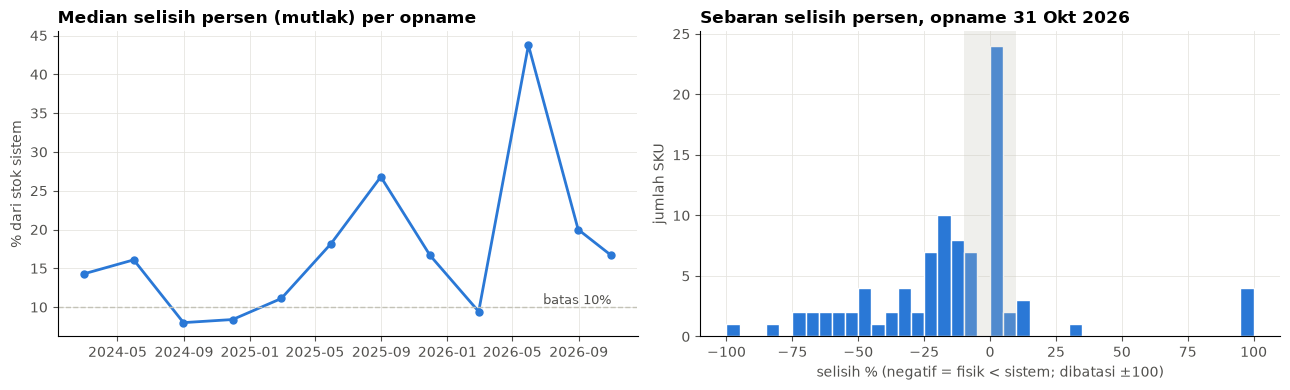

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
d = per_opname["median_selisih_persen_mutlak"]
ax1.plot(d.index, d.values, color=WARNA_UTAMA, marker="o", markersize=5)
ax1.set_title("Median selisih persen (mutlak) per opname")
ax1.set_ylabel("% dari stok sistem")
ax1.axhline(10, color=WARNA_REDUP, linestyle="--", linewidth=1)
ax1.text(d.index[-1], 10, " batas 10%", va="bottom", ha="right", fontsize=9, color="#52514e")
d = okt["selisih_persen"].dropna().clip(-100, 100)
ax2.hist(d, bins=np.arange(-100, 105, 5), color=WARNA_UTAMA, edgecolor="white")
ax2.axvspan(-10, 10, color=WARNA_REDUP, alpha=0.25, linewidth=0)
ax2.set_title("Sebaran selisih persen, opname 31 Okt 2026")
ax2.set_xlabel("selisih % (negatif = fisik < sistem; dibatasi ±100)")
ax2.set_ylabel("jumlah SKU")
plt.tight_layout()
plt.show()

**Insight:**
- **Median selisih persen (mutlak) dari 12 opname adalah 16,23%.** Hanya tiga opname yang mediannya di bawah 10% (Agu 2024, Nov 2024, dan Feb 2026).
- **Opname 31 Okt 2026: 64 dari 97 SKU selisihnya di atas 10%**, terdiri dari 58 SKU normal dan **6 SKU abnormal** yang stok sistemnya nol atau minus padahal barangnya ada di gudang: **DCSK** (sistem 0, fisik 9), **BRVXN** (−3 / 3), **FSTN100** (−7 / 3), **KCL** (−227 / 105), **RGNTB** (−3 / 2), dan **UREA** (−31 / 54). Catatan keenam SKU inilah yang paling parah, sehingga perlu dihitung paling sering.
- Arah selisih umumnya **negatif** (fisik < sistem). Tiga penyebab yang terlihat dari data:
  1. **Pemecahan tidak tercatat:** stok sistem KCL Curah (−227) dan Urea Curah (−31) sudah negatif sebelum opname, padahal fisiknya 105 dan 54 kemasan. Artinya kemasan sudah dipecah dan dijual, tetapi pemecahannya tidak dicatat.
  2. **Penjualan yang ditolak** (Polybag, Pupuk Amazing) tidak mengurangi stok sistem, sehingga stok sistem SKU ini lebih tinggi dari fisik. Contohnya Polybag 35x35: sistem 30, fisik 1.
  3. **Penjualan online** baru mengurangi stok di akhir bulan. Karena semua opname dilakukan di akhir bulan setelah laporan online diimpor, faktor ini tidak berpengaruh di data ini.
- **SKU yang perlu dihitung lebih sering:** SKU dengan selisih > 10% berulang, terutama kemasan curah (KCL, Urea, Dolomit) dan polybag. Untuk kemasan curah, yang perlu diperbaiki terutama **pencatatan pemecahan**, bukan frekuensi opname.

### Pertanyaan 10 (Q10)
**Dari 70 SKU yang punya data marketplace (Shopee, Tokopedia, TikTok Shop; Feb 2025 sampai Okt 2026), 10 produk mana yang paling banyak diklik tetapi jarang dibeli (pesanan dibagi klik di bawah median semua produk)?**

- Satu **produk = satu SKU**, dengan klik dan pesanan dijumlahkan dari ketiga kanal selama seluruh periode.
- Konversi = total pesanan ÷ total klik. Median dihitung dari semua SKU di data metrik.

In [35]:
print("SKU per kanal:", metrik.groupby("kanal")["sku"].nunique().to_dict(), "| SKU unik semua kanal:", metrik["sku"].nunique())
q10 = metrik.groupby("sku").agg(impresi=("impresi", "sum"), klik=("klik", "sum"), pesanan=("pesanan", "sum"),
                                kanal=("kanal", "nunique"), harga_tayang_median=("harga_tayang", "median"),
                                rating_median=("rating", "median"))
q10["konversi_%"] = (q10["pesanan"] / q10["klik"] * 100).round(2)
q10["nama"] = q10.index.map(info["nama"])
median_konversi = q10["konversi_%"].median()
kandidat_q10 = q10[q10["konversi_%"] < median_konversi].nlargest(10, "klik")
print("Produk:", len(q10), "| median konversi:", round(median_konversi, 2), "%")
display(kandidat_q10[["nama", "klik", "pesanan", "konversi_%", "harga_tayang_median", "rating_median"]])

SKU per kanal: {'Shopee': 70, 'TikTok Shop': 70, 'Tokopedia': 70} | SKU unik semua kanal: 70
Produk: 70 | median konversi: 3.44 %


,nama,klik,pesanan,konversi_%,harga_tayang_median,rating_median
sku,,,,,,
KOVINPLUS,Kovin Plus 80P,4543.0,155.0,3.41,4988.0,4.7
GRNSTIK,Green Stick,1401.0,48.0,3.43,19100.0,4.6
FARMQUAT250,Farmquat 276 SL,1319.0,45.0,3.41,27982.0,4.6
JARINGBSR,Jaring Buah Besar,1236.0,37.0,2.99,8032.0,4.6
BFS1L,Bufos 150 SL,1087.0,37.0,3.40,82688.0,4.7
VLGR400,Vulgar 865 SL,1050.0,33.0,3.14,55070.0,4.6
AGL,Amazing Grow Booster Kelengkeng,1026.0,34.0,3.31,32488.0,4.8
FENITE100,Fenite 150 OD,1002.0,34.0,3.39,152417.0,4.6
EM4K,EM4 Pertanian,987.0,29.0,2.94,54080.0,4.6


In [36]:
# Konversi per kanal untuk 10 produk tersebut (apakah rendah di semua kanal atau hanya satu kanal?)
per_kanal_q10 = metrik[metrik["sku"].isin(kandidat_q10.index)].groupby(["sku", "kanal"])[["klik", "pesanan"]].sum()
konv_kanal = (per_kanal_q10["pesanan"] / per_kanal_q10["klik"] * 100).round(2).unstack()[["Shopee", "Tokopedia", "TikTok Shop"]]
konv_kanal.index = konv_kanal.index.map(info["nama"])
median_per_kanal = (metrik.groupby(["sku", "kanal"])[["klik", "pesanan"]].sum()
                    .pipe(lambda d: d["pesanan"] / d["klik"] * 100).groupby("kanal").median().round(2))
print("Median konversi per kanal (semua SKU):", median_per_kanal.to_dict())
konv_kanal

Median konversi per kanal (semua SKU): {'Shopee': 3.68, 'TikTok Shop': 3.74, 'Tokopedia': 2.8}


kanal,Shopee,Tokopedia,TikTok Shop
sku,,,
Amazing Grow Booster Kelengkeng,2.50,2.95,4.24
Bufos 150 SL,3.77,2.65,3.48
EM4 Pertanian,2.81,2.45,3.70
Farmquat 276 SL,3.70,3.05,3.18
Fenite 150 OD,3.02,2.81,4.17
Green Stick,3.62,2.62,3.88
Jaring Buah Besar,2.86,1.87,3.84
Kovin Plus 80P,3.73,3.65,3.05
MekarMAP,2.70,2.06,1.70


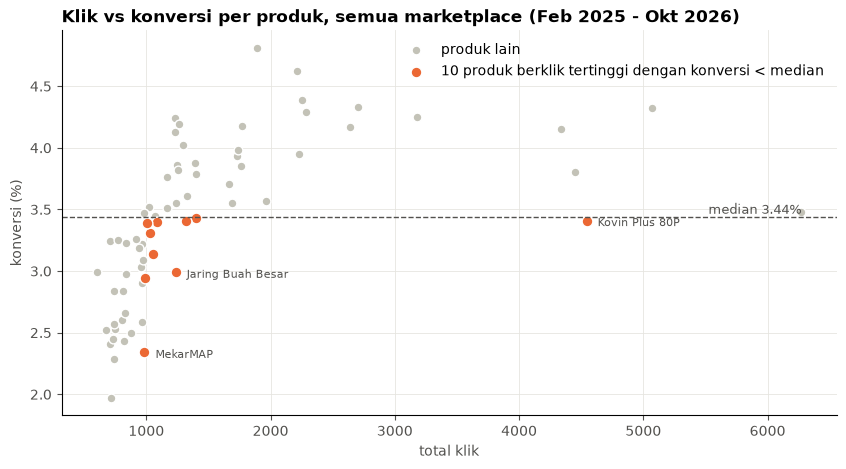

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))
lain = q10[~q10.index.isin(kandidat_q10.index)]
ax.scatter(lain["klik"], lain["konversi_%"], s=40, color=WARNA_REDUP, label="produk lain", edgecolor="white", linewidth=1)
ax.scatter(kandidat_q10["klik"], kandidat_q10["konversi_%"], s=60, color=WARNA_KANAL["Shopee"],
           label="10 produk berklik tertinggi dengan konversi < median", edgecolor="white", linewidth=1)
ax.axhline(median_konversi, color="#52514e", linestyle="--", linewidth=1)
ax.text(q10["klik"].max(), median_konversi, f"median {median_konversi:.2f}%", va="bottom", ha="right", fontsize=9, color="#52514e")
for sku in ["KOVINPLUS", "JARINGBSR", "MEKARMAP1"]:                 # label hanya untuk titik yang tidak bertumpuk
    baris = kandidat_q10.loc[sku]
    ax.annotate(baris["nama"], (baris["klik"], baris["konversi_%"]), xytext=(8, -4), textcoords="offset points",
                fontsize=8, color="#52514e")
ax.set_title("Klik vs konversi per produk, semua marketplace (Feb 2025 - Okt 2026)")
ax.set_xlabel("total klik")
ax.set_ylabel("konversi (%)")
ax.legend(loc="upper right")
plt.show()

**Insight:**
- Data metrik berisi **70 SKU yang sama di ketiga kanal** (210 pasangan SKU-kanal). Satu produk dihitung sebagai satu SKU, dengan klik dan pesanan ketiga kanal dijumlahkan.
- Median konversi 70 produk adalah **3,44%**. Sepuluh produk berklik tertinggi yang konversinya di bawah median: **Kovin Plus 80P** (4.543 klik, 3,41%), Green Stick, Farmquat 276 SL, **Jaring Buah Besar** (2,99%), Bufos 150 SL, Vulgar 865 SL, Amazing Grow Booster Kelengkeng, Fenite 150 OD, EM4 Pertanian, dan **MekarMAP** (konversi terendah, 2,34%).
- Sebagian besar hanya sedikit di bawah median (3,3–3,4%). Yang paling perlu diperiksa adalah **MekarMAP, EM4 Pertanian, dan Jaring Buah Besar** (< 3%).
- Konversi Tokopedia lebih rendah di hampir semua produk (median 2,8% vs 3,7% di Shopee dan TikTok Shop). MekarMAP rendah di semua kanal, terutama TikTok Shop (1,7%), sedangkan Amazing Grow Booster Kelengkeng hanya rendah di Shopee (2,5%). Tindakannya bisa dimulai dari kanal dengan konversi terendah: foto, judul, dan harga tayang listing di kanal itu.
- Kovin Plus 80P paling banyak diklik (harga tayang Rp4.988) dan konversinya hampir menyamai median, jadi produk ini lebih tepat dipertahankan daripada diubah.

## 4. Pola Penjualan untuk Modeling
Bagian ini tidak menjawab pertanyaan tertentu, tetapi menyiapkan keputusan untuk forecast unit per SKU per bulan (Q7) di `03_modeling.ipynb`.

In [38]:
unit_sku_bulan = items.pivot_table(index="sku", columns="bulan", values="qty", aggfunc="sum", fill_value=0)
bulan_12 = [b for b in unit_sku_bulan.columns if b >= pd.Period("2025-11")]
bulan_terjual = (unit_sku_bulan[bulan_12] > 0).sum(axis=1)
pola = pd.cut(bulan_terjual, bins=[-1, 0, 3, 9, 12], labels=["tidak terjual", "jarang (1-3 bulan)", "sedang (4-9 bulan)", "rutin (10-12 bulan)"])
ringkas_pola = pd.DataFrame({"sku": pola.value_counts().sort_index(),
                             "porsi_unit_12_bulan_%": (unit_sku_bulan[bulan_12].sum(axis=1).groupby(pola, observed=False).sum()
                                                       / unit_sku_bulan[bulan_12].values.sum() * 100).round(1)})
display(ringkas_pola)
print("Unit per bulan per SKU (12 bulan terakhir, SKU yang terjual):")
print(unit_sku_bulan.loc[bulan_terjual > 0, bulan_12].stack().describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1).to_dict())

,sku,porsi_unit_12_bulan_%
tidak terjual,6,0.0
jarang (1-3 bulan),17,0.1
sedang (4-9 bulan),20,0.9
rutin (10-12 bulan),140,99.0


Unit per bulan per SKU (12 bulan terakhir, SKU yang terjual):
{'count': 2124.0, 'mean': 20.8, 'std': 43.1, 'min': 0.0, '25%': 2.0, '50%': 8.0, '75%': 20.0, '90%': 47.7, 'max': 475.0}


**Insight:**
- **140 SKU terjual rutin** (10–12 bulan dari 12 bulan terakhir) dan menyumbang **99% unit**. Hanya 37 SKU yang jarang atau sedang, dengan porsi unit sekitar 1%.
- Unit per SKU per bulan kecil: median 8 unit, persentil 90 = 48 unit. Angka kecil seperti ini membuat error persen mudah besar, jadi Q9 memakai **WAPE** (error total ÷ unit total), bukan rata-rata error persen per SKU.
- **Keputusan untuk modeling:** forecast fokus pada 140 SKU rutin. SKU jarang terjual cukup memakai metode sederhana (rata-rata atau nol), karena dampaknya ke unit total sangat kecil.

### 4.2 Apakah ada pola musim?
Untuk melihat musim, dipakai **offline saja** (tersedia 3 tahun penuh). Online baru dibuka 2025 sehingga kenaikannya akan terbaca sebagai tren, bukan musim.

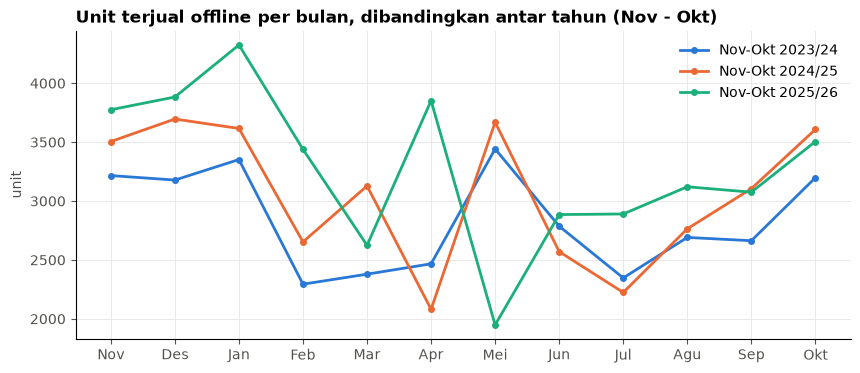

,Nov,Des,Jan,Feb,Mar,Apr,Mei,Jun,Jul,Agu,Sep,Okt
tahun_buku,,,,,,,,,,,,
2023/24,3216,3178,3352,2294,2379,2467,3442,2786,2347,2691,2663,3198
2024/25,3505,3696,3616,2653,3128,2081,3669,2570,2224,2764,3105,3608
2025/26,3775,3883,4325,3439,2624,3852,1948,2885,2890,3121,3075,3505


In [39]:
off_bulanan = items[items["kanal"] == "Offline"].groupby("bulan")["qty"].sum()
musim = pd.DataFrame({"tahun_buku": [f"{(b - 10).year}/{str((b - 10).year + 1)[-2:]}" for b in off_bulanan.index],   # Nov-Okt
                      "bulan_ke": [((b.month - 11) % 12) + 1 for b in off_bulanan.index], "unit": off_bulanan.values})
nama_bulan = ["Nov", "Des", "Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt"]
fig, ax = plt.subplots(figsize=(10, 4))
for warna, (tahun, d) in zip([WARNA_KANAL["Offline"], WARNA_KANAL["Shopee"], WARNA_KANAL["Tokopedia"]], musim.groupby("tahun_buku")):
    ax.plot(d["bulan_ke"], d["unit"], color=warna, marker="o", markersize=4, label=f"Nov-Okt {tahun}")
ax.set_xticks(range(1, 13), nama_bulan)
ax.set_title("Unit terjual offline per bulan, dibandingkan antar tahun (Nov - Okt)")
ax.set_ylabel("unit")
ax.legend()
plt.show()
musim.pivot(index="tahun_buku", columns="bulan_ke", values="unit").set_axis(nama_bulan, axis=1)

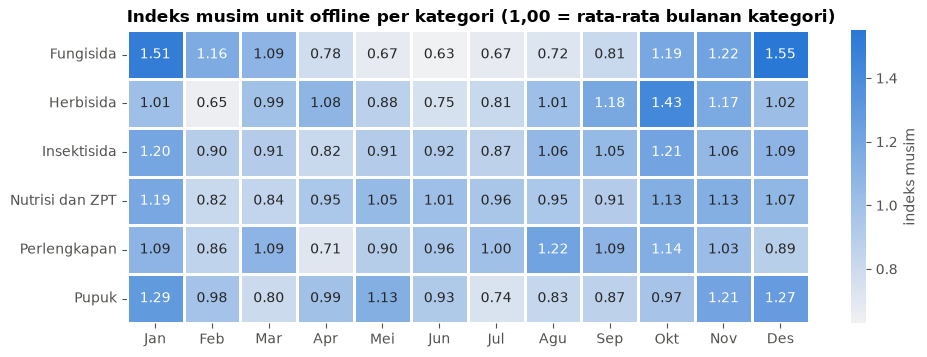

In [40]:
# Musim per kategori: unit offline per bulan kalender dibagi rata-rata bulanan kategori itu (1 = bulan biasa)
off_kat = items[items["kanal"] == "Offline"].assign(bulan_kalender=lambda d: d["tanggal"].dt.month)
indeks = off_kat.pivot_table(index="kategori", columns="bulan_kalender", values="qty", aggfunc="sum")
indeks = indeks.div(indeks.mean(axis=1), axis=0).round(2)
indeks.columns = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(indeks, cmap=sns.light_palette(WARNA_UTAMA, as_cmap=True), annot=True, fmt=".2f", linewidths=2, linecolor="white",
            cbar_kws={"label": "indeks musim"}, ax=ax)
ax.set_title("Indeks musim unit offline per kategori (1,00 = rata-rata bulanan kategori)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.show()

**Insight:**
- Pola tahunan offline berulang: **Nov–Jan ramai**, lalu turun di **Feb dan Apr/Mei** (bergantian antar tahun), dan naik lagi menjelang **Okt**. Ini sejalan dengan musim tanam: kebutuhan pupuk dan pestisida naik di awal musim hujan.
- Per kategori, **Fungisida** paling musiman (Des 1,55 dan Jan 1,51 vs Jun 0,63), wajar karena penyakit jamur meningkat di musim hujan. **Pupuk** naik di Nov–Jan (1,21–1,29), dan **Herbisida** memuncak di Okt (1,43).
- **Keputusan untuk modeling:** model perlu menangkap musim tahunan (fitur bulan atau nilai bulan yang sama tahun lalu). Rata-rata bergerak 3 bulan (baseline Q9) akan tertinggal saat masuk dan keluar musim ramai.

### 4.3 Porsi kanal online dari waktu ke waktu

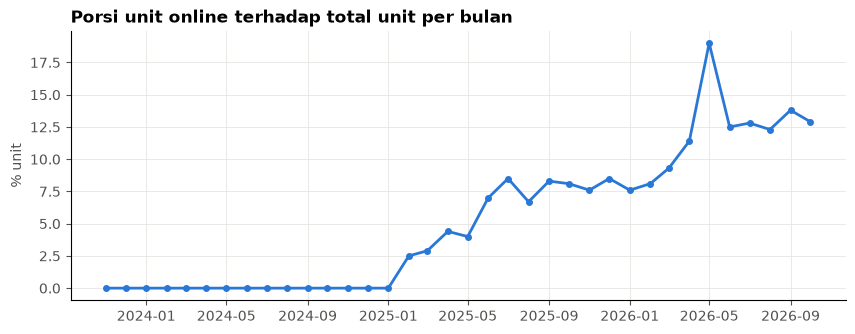

Porsi unit online, 6 bulan terakhir (%): {'2026-05': 19.0, '2026-06': 12.5, '2026-07': 12.8, '2026-08': 12.3, '2026-09': 13.8, '2026-10': 12.9}


In [41]:
porsi_online = (unit_kanal[["Shopee", "Tokopedia", "TikTok Shop"]].sum(axis=1) / unit_kanal["Total"] * 100).round(1)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(porsi_online.index.to_timestamp(), porsi_online.values, color=WARNA_UTAMA, marker="o", markersize=4)
ax.set_title("Porsi unit online terhadap total unit per bulan")
ax.set_ylabel("% unit")
plt.show()
print("Porsi unit online, 6 bulan terakhir (%):", {str(b): v for b, v in porsi_online.tail(6).items()})

**Insight:**
- Porsi unit online naik sejak Feb 2025 dan stabil di **sekitar 12–14% unit** per bulan sejak Jun 2026 (puncaknya 19% di Mei 2026, ketika penjualan offline turun).
- Untuk forecast Q7, total semua kanal sebaiknya dimodelkan dari tanggal pesanan (`order_date`), dan perlu diingat bahwa riwayat online baru ada 21 bulan (TikTok Shop 17 bulan), sehingga musim tahunannya terutama dipelajari dari data offline.

## 5. Conclusion

- **Conclusion pertanyaan 1:** total omzet 36 bulan Rp3,49 miliar (116.405 unit), dengan offline 92,6% omzet. Okt 2026 dibanding Sep 2026: omzet **naik 17,2%** (unit +12,8%). Shopee tumbuh paling cepat (omzet +26,8%), sedangkan Tokopedia (−3,4%) dan TikTok Shop (−6,7%) turun.
- **Conclusion pertanyaan 2:** dalam 12 bulan terakhir, 10 produk teratas menyumbang 35,6% dari omzet Rp1,41 miliar. MKP Pak Tani menjadi produk omzet tertinggi (6,4%) dan KCL Curah produk unit tertinggi (4.025 unit). Urutan 6 kategori menurut omzet: Insektisida (34,9%), Pupuk (25,9%), Herbisida (14,7%), Fungisida (12,3%), Nutrisi dan ZPT (9,5%), dan Perlengkapan (2,7%).
- **Conclusion pertanyaan 3:** margin bersih offline 31,6%, Tokopedia 25,8%, Shopee 23,6%, dan TikTok Shop 11,4%, karena biaya platform TikTok Shop mencapai 23,7% omzet. Per kategori, margin tertinggi Pupuk (31,6%) dan Nutrisi dan ZPT (31,1%).
- **Conclusion pertanyaan 4:** per 31 Okt 2026, **2 SKU perlu dipecah** (Kapur Dolomite, Emkape 500 g) dan **18 SKU perlu dipesan ulang** (termasuk induk Fertiphos), dengan aturan titik pesan ulang = rata-rata harian × lead time + stok pengaman (2 unit; 1 karung untuk induk 50 kg) dan batas memecah 2 unit. 19 SKU tidak laku 90 hari ditampilkan sebagai daftar barang menumpuk.
- **Conclusion pertanyaan 5:** 8 SKU berstok minus dikecualikan (7 perlu cek fisik, ditambah `EXTRAPCKG` yang memang tidak dilacak stoknya), dan 19 SKU tanpa penjualan 90 hari diberi label tanpa angka. Dari SKU aktif lainnya, median stok cukup 37,5 hari, dan **4 dari 156 SKU yang dibeli dari supplier** stoknya habis sebelum lead time, sehingga harus dipesan paling dulu.
- **Conclusion pertanyaan 6:** median selisih persen opname **16,23%**. Pada opname 31 Okt 2026, **64 dari 97 SKU** selisihnya di atas 10% (58 SKU normal dan 6 SKU abnormal berstok sistem nol atau minus). Penyebab utamanya pemecahan kemasan curah yang tidak dicatat dan penjualan yang ditolak di wrangling.
- **Conclusion pertanyaan 10:** dari 70 produk (median konversi 3,44%), 10 produk berklik tertinggi dengan konversi di bawah median dipimpin Kovin Plus 80P. Yang paling perlu diperbaiki listing-nya adalah MekarMAP, EM4 Pertanian, dan Jaring Buah Besar.
- **Bekal untuk modeling (Q7–Q9):** 140 SKU rutin menyumbang 99% unit; ada musim tahunan yang jelas (ramai Nov–Jan, sepi Feb–Mei), sehingga baseline rata-rata 3 bulan akan tertinggal saat musim berganti; target forecast memakai data strict (`penjualan_ambigu` tidak dimasukkan); jumlah pesanan Q8 dihitung dari forecast Q7 dan `reorder_settings`.